# Testing for Uncovered Interest Parity (UIP) in PLFs

In [12]:
import os
import pandas as pd
from statsmodels.regression.linear_model import OLS
import statsmodels.api as sm
from itertools import combinations
import numpy as np
import matplotlib.pyplot as plt

os.chdir(os.path.expanduser('~/defi-plf-analysis'))
from compounds_research.compound import utils
from compounds_research import settings
from compounds_research.compound.fetch_exchange_rates import make_exchange_rate_df

In [13]:
import sys, os
sys.path.insert(0, os.path.join('.', 'compounds_research', 'compound'))
import importlib
import fetch_exchange_rates_defillama
importlib.reload(fetch_exchange_rates_defillama)
from fetch_exchange_rates_defillama import cache_all_token_usd_prices

cache_all_token_usd_prices(start_date='2020-02-01', end_date='2020-05-31')

bat: already cached, skipping.
zrx: already cached, skipping.
usdc: already cached, skipping.
dai: already cached, skipping.
wbtc: already cached, skipping.
eth: already cached, skipping.
Done. (rep, sai use the existing manually-cleaned files and need no separate caching step.)


In [14]:
tokens = []
for k in settings.COMPOUND_TOKEN_TRANSLATOR:
    tokens.append(settings.COMPOUND_TOKEN_TRANSLATOR[k])

if 'wbtc' in tokens: tokens.remove('wbtc') #Data too messy for WBTC

In [16]:

def regression_runner(frequency: str, side: str):
    '''
    Run customized UIP regression for given frequency of data and side of market.
    :side: 'borrow' or 'supply'
    :frequency: e.g., 'D' or 'W'
    '''
    regression_results = {}
    regression_results['pair'] = []
    regression_results['n-obs'] = []
    regression_results['alpha'] = []
    regression_results['beta'] = []
    regression_results['r-squared'] = []
    regression_results['p-value_alpha'] = []
    regression_results['p-value_beta'] = []
    regression_results['f-test-p-value'] = []
    regression_results['beta-one'] = []

    UIP_holds = {}
    UIP_not_holds = {}
    for market in combinations(tokens, 2):
        quote_token = market[1]
        base_token = market[0]
        
        if quote_token == 'rep' and base_token == 'sai':
            continue

        try:
            df = utils.make_ex_rate_and_interest_rate_df(quote_token=quote_token, 
                                                        base_token=base_token, 
                                                        rate_type=side+'_rates', 
                                                        frequency=frequency, 
                                                        limit=1000)
            lag_length = int(len(df)**0.25)
        except:
            print('Error making dataframe for ' + str(quote_token) + ' to ' + str(base_token))
            continue
        
        if quote_token == 'usdc' and base_token == 'eth':
            print(df)
        
        df['i_rate_diff'] = df[quote_token] - df[base_token]
        df['log_prices'] = np.log(df[str(base_token)+ '_' + str(quote_token)])
        df['log_prices_diff'] = df['log_prices'].diff()
        df['ex_rate_diff'] = df['log_prices_diff'].shift(-1)
        
        df = df.dropna()
        print("Plot; base token: " + str(base_token) + ', Quote token: ' + str(quote_token))
        df[['i_rate_diff', 'ex_rate_diff']].plot()
        plt.show()

        df[[str(quote_token), str(base_token)]].plot()
        plt.show()

        df[str(base_token)+ '_' + str(quote_token)].plot()
        plt.show()

        model = OLS(endog=df['ex_rate_diff'], exog=sm.add_constant(df['i_rate_diff']))
        res = model.fit(cov_type='HAC', cov_kwds={'maxlags':lag_length})

        regression_results['pair'].append(base_token + '_' + quote_token)
        regression_results['pair'].append(' ')

        regression_results['n-obs'].append(int(res.nobs))
        regression_results['n-obs'].append(' ')
        
        regression_results['alpha'].append("{:.2f}".format(res.params.iloc[0]))
        regression_results['alpha'].append('(' + str("{:.2f}".format(res.bse.iloc[0])) + ')')

        regression_results['beta'].append(res.params.iloc[1])
        regression_results['beta'].append('(' + str("{:.2f}".format(res.bse.iloc[1])) + ')')

        regression_results['r-squared'].append("{:.2f}".format(res.rsquared))
        regression_results['r-squared'].append(' ')

        regression_results['p-value_alpha'].append("{:.2f}".format(res.pvalues.iloc[0]))
        regression_results['p-value_alpha'].append(' ')

        regression_results['p-value_beta'].append("{:.2f}".format(res.pvalues.iloc[1]))
        regression_results['p-value_beta'].append(' ')

        #Test beta=1
        hypotheses = '(i_rate_diff = 1)'
        try:
            f_test = res.f_test(hypotheses)
        except:
            print("Error; base token: " + str(base_token) + ', Quote token: ' + str(quote_token))
            continue

        regression_results['beta-one'].append("{:.2f}".format(f_test.pvalue))
        regression_results['beta-one'].append(' ')

        #Test joint null
        hypotheses = '(const = 0), (i_rate_diff = 1)'
        try:
            f_test = res.f_test(hypotheses)
        except:
            continue

        regression_results['f-test-p-value'].append("{:.2f}".format(f_test.pvalue))
        regression_results['f-test-p-value'].append(' ')

        if f_test.pvalue >= 0.05:
            print("UIP holds.")
            UIP_holds[str(base_token)+ '_' + str(quote_token)] = f_test.pvalue
        else:
            print("UIP does not hold.")
            UIP_not_holds[str(base_token)+ '_' + str(quote_token)] = f_test.pvalue
        
    df_results = pd.DataFrame(regression_results)
    print('UIP holds: ' + str(UIP_holds))
    print('UIP does not hold: ' + str(UIP_not_holds))
    print(df_results.to_latex(index=False))
            

Plot; base token: eth, Quote token: bat


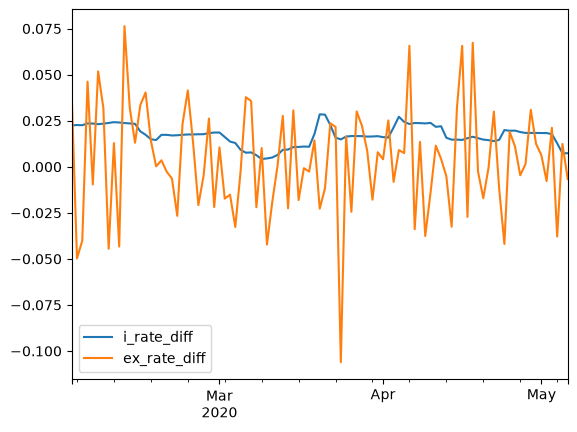

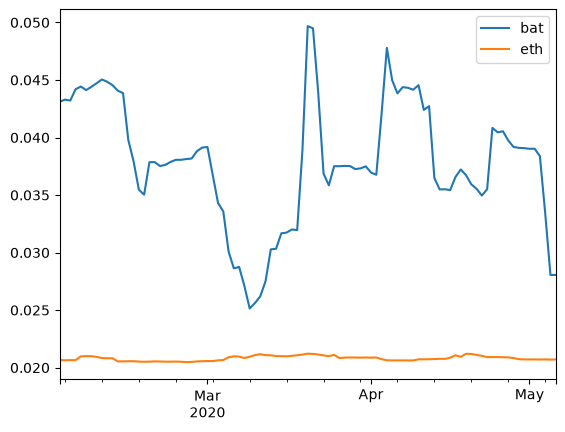

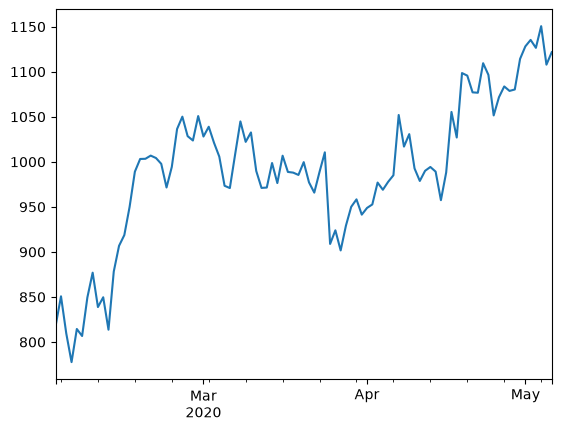

UIP does not hold.
Plot; base token: eth, Quote token: zrx


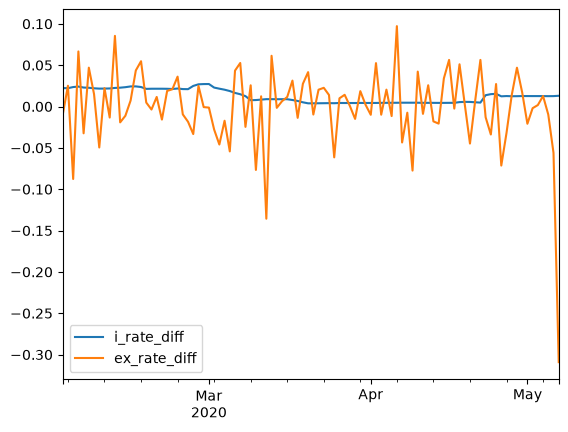

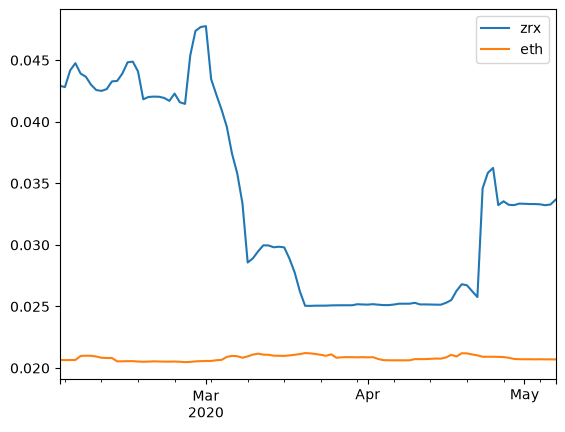

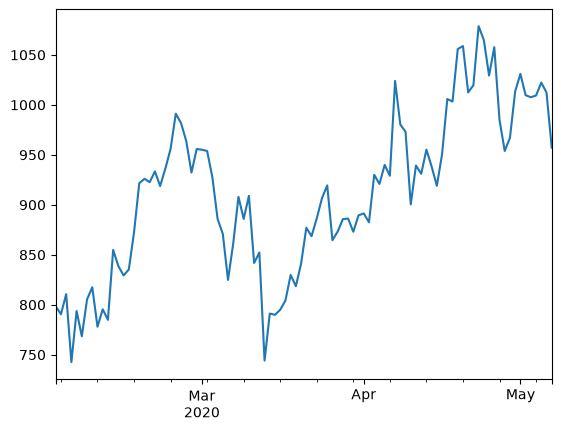

UIP does not hold.
              eth_usdc      usdc       eth
2020-02-01  179.284847  0.084948  0.021066
2020-02-02  183.096449  0.084630  0.020662
2020-02-03  188.504691  0.084230  0.020640
2020-02-04  189.334919  0.083986  0.020652
2020-02-05  188.327844  0.084794  0.020655
...                ...       ...       ...
2020-05-04  210.007876  0.045250  0.020714
2020-05-05  206.936404  0.046786  0.020702
2020-05-06  204.675484  0.047515  0.020707
2020-05-07  201.167493  0.047500  0.020697
2020-05-08  211.831291  0.048579  0.020702

[98 rows x 3 columns]
Plot; base token: eth, Quote token: usdc


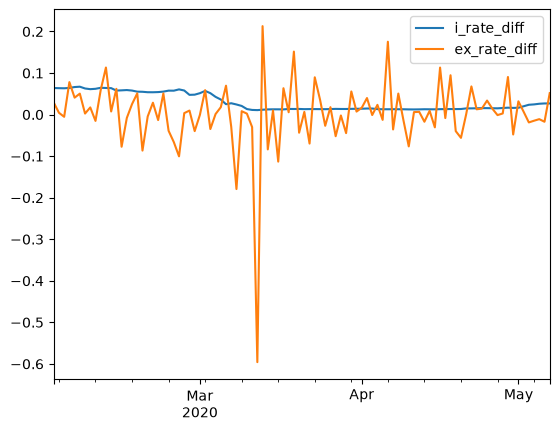

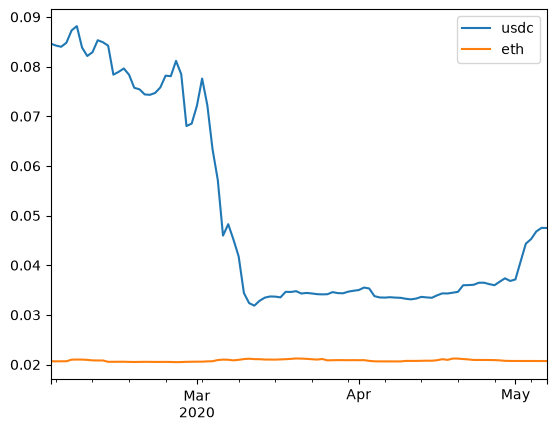

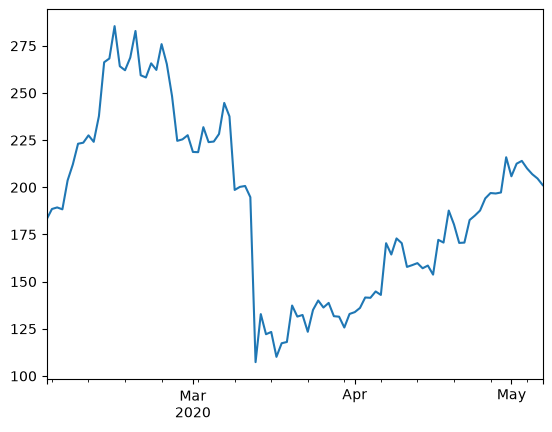

UIP does not hold.
Plot; base token: eth, Quote token: dai


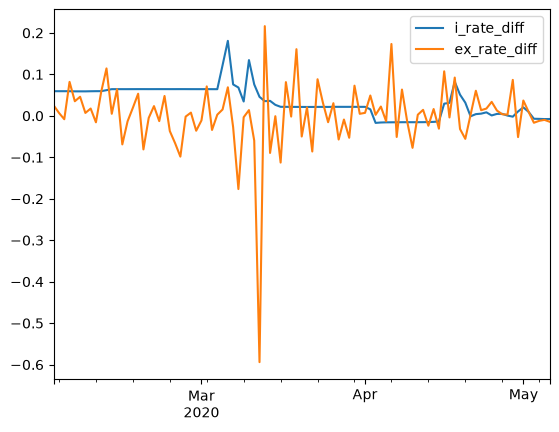

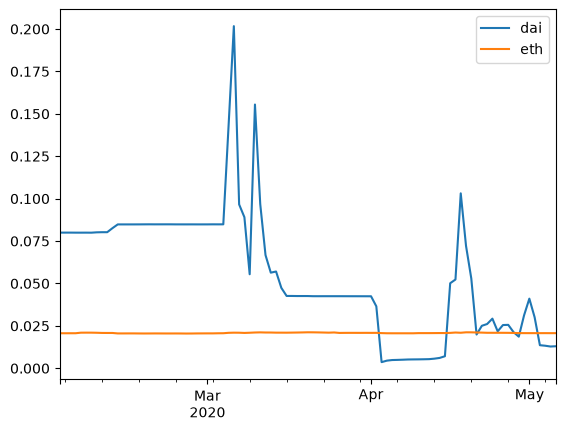

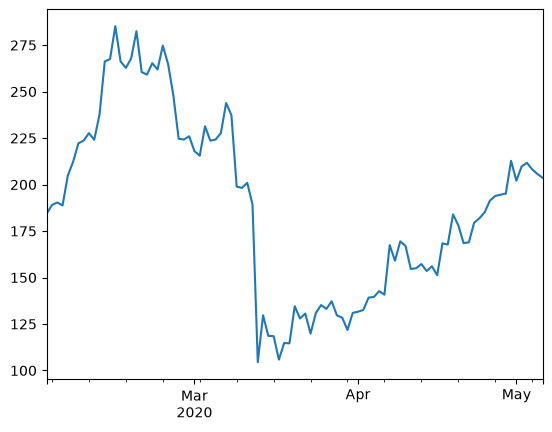

UIP does not hold.
Plot; base token: eth, Quote token: sai


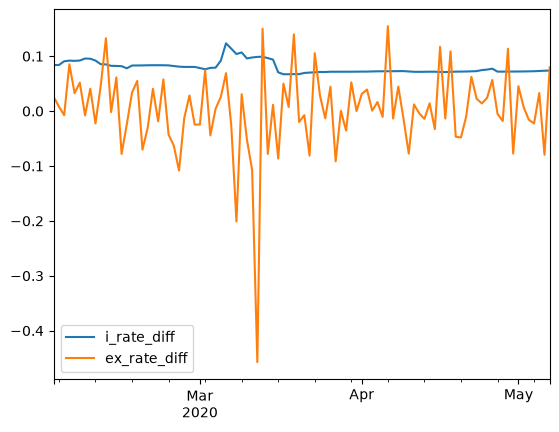

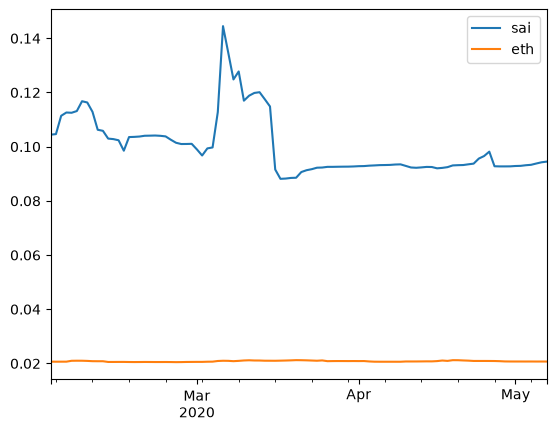

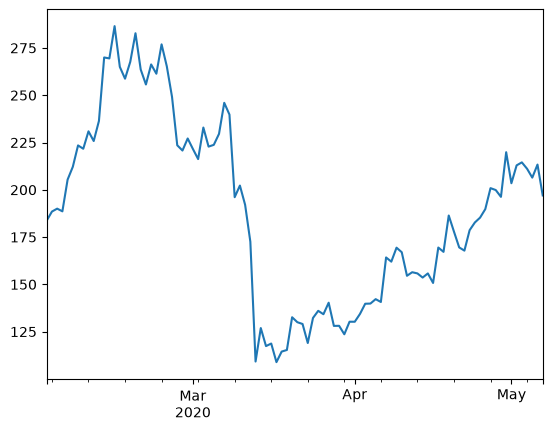

UIP does not hold.
Plot; base token: eth, Quote token: rep


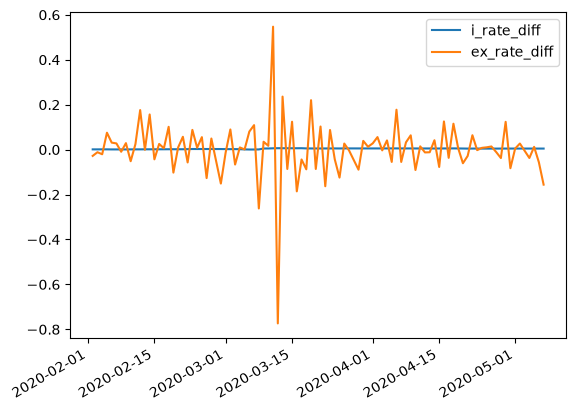

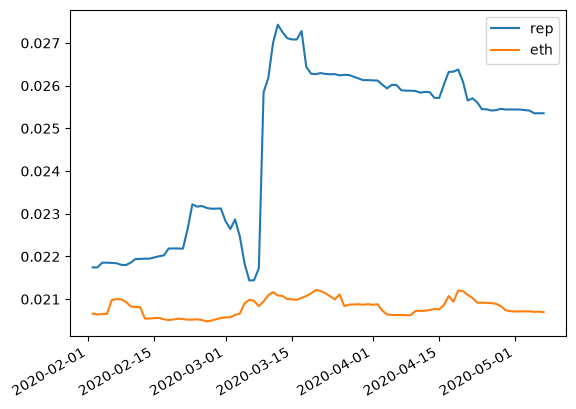

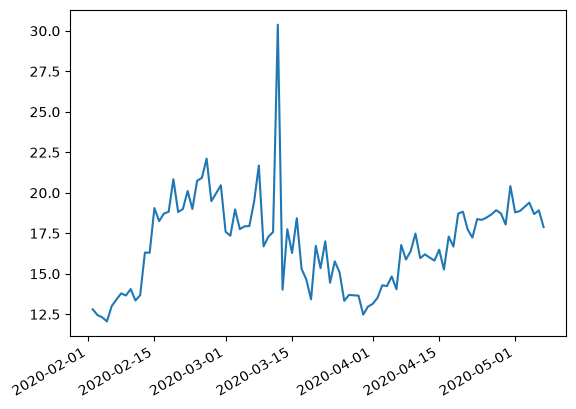

UIP holds.
Plot; base token: bat, Quote token: zrx


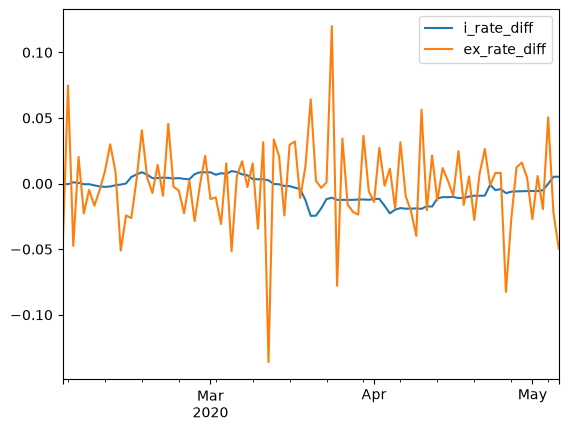

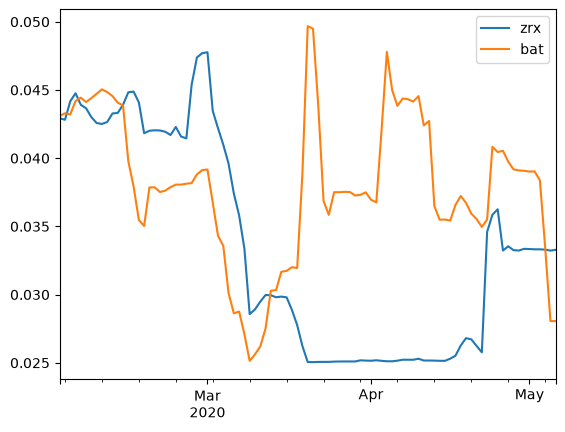

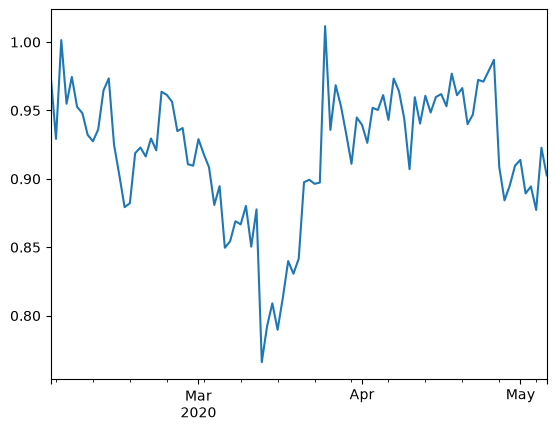

UIP does not hold.
Plot; base token: bat, Quote token: usdc


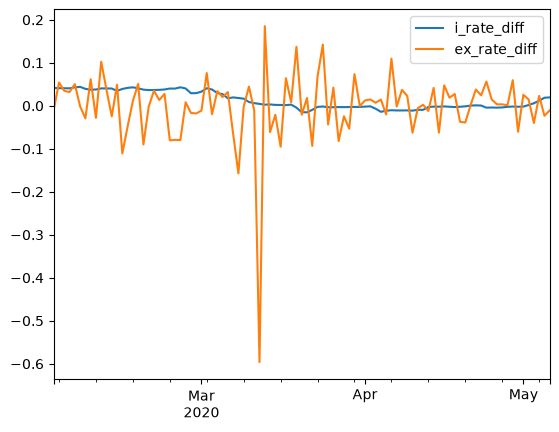

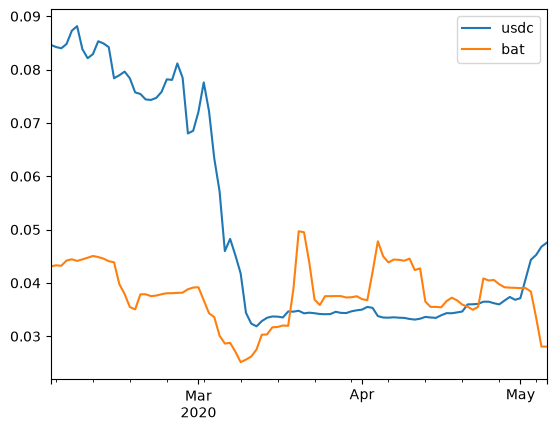

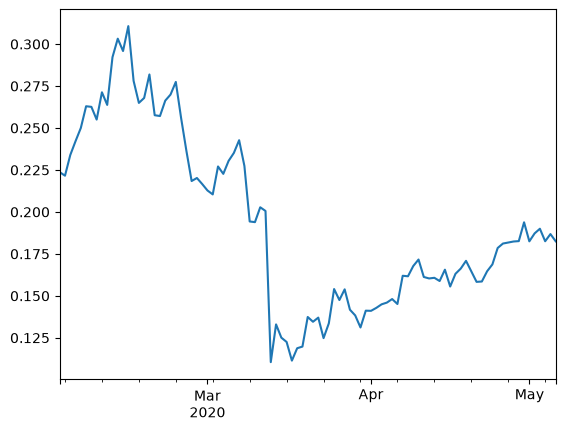

UIP does not hold.
Plot; base token: bat, Quote token: dai


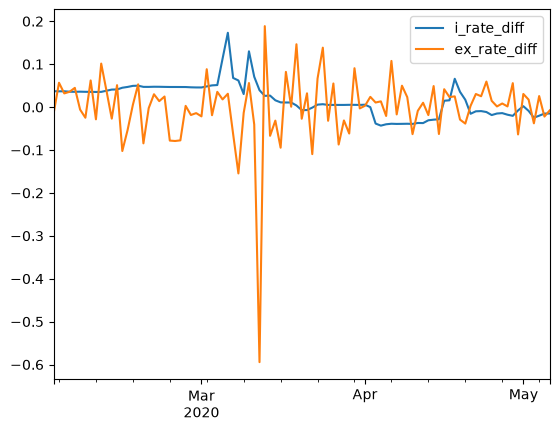

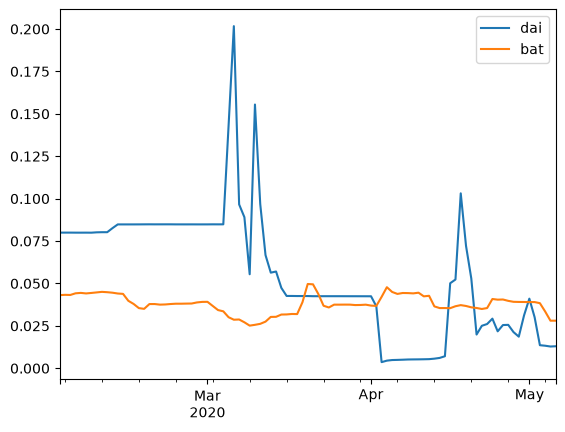

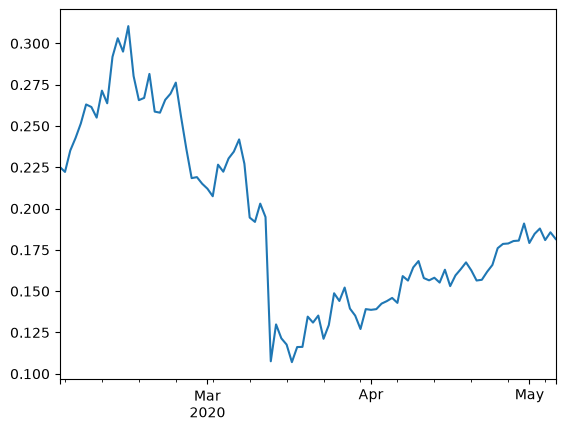

UIP does not hold.
Plot; base token: bat, Quote token: sai


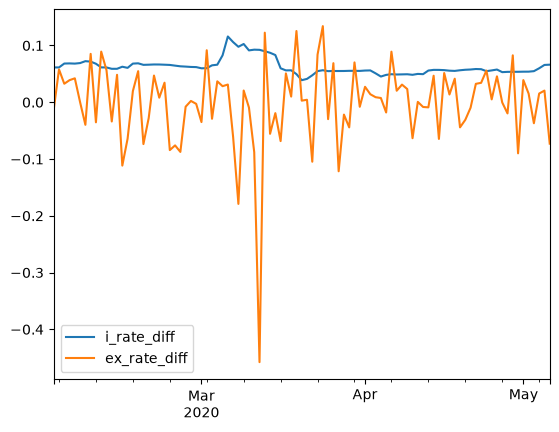

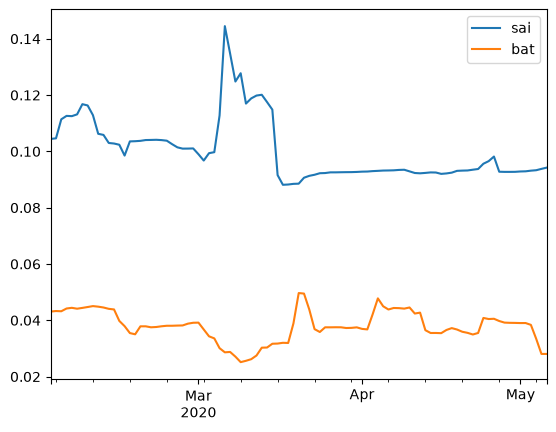

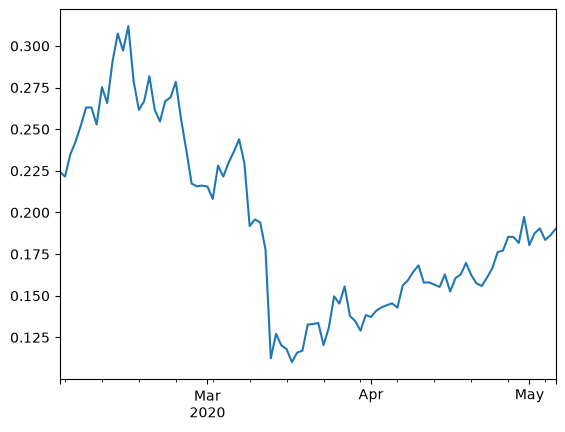

UIP does not hold.
Plot; base token: bat, Quote token: rep


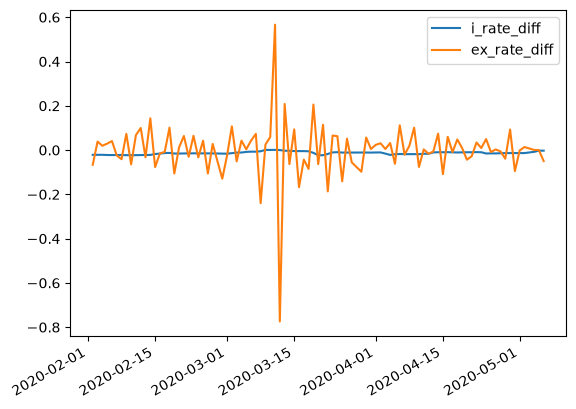

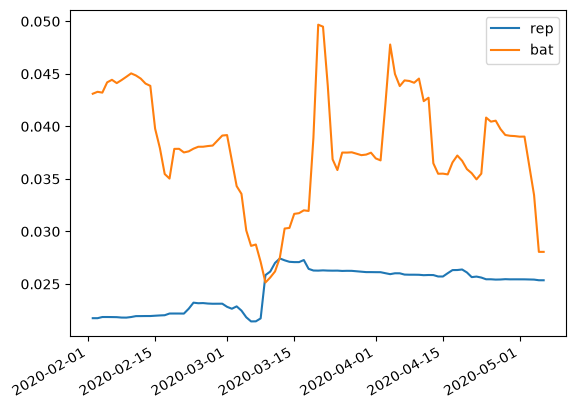

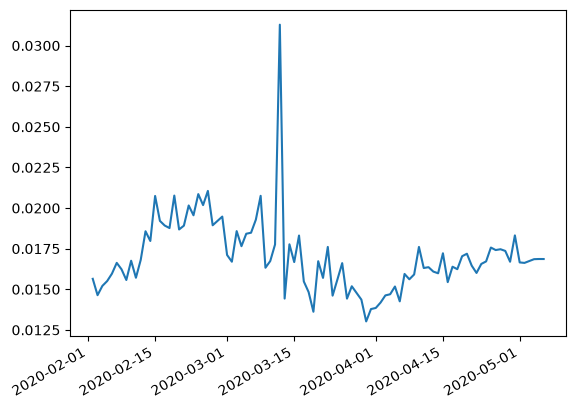

UIP does not hold.
Plot; base token: zrx, Quote token: usdc


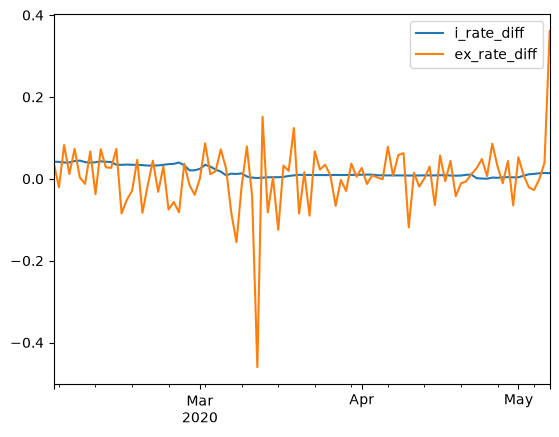

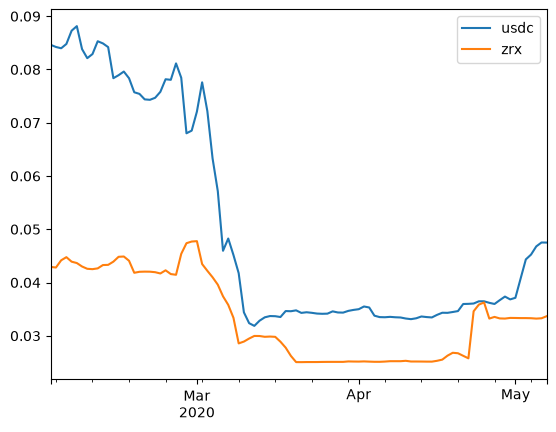

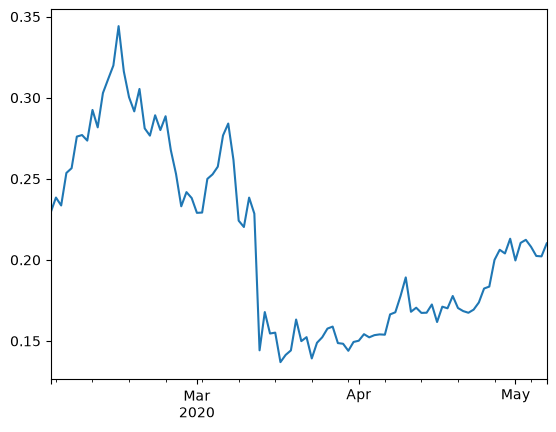

UIP does not hold.
Plot; base token: zrx, Quote token: dai


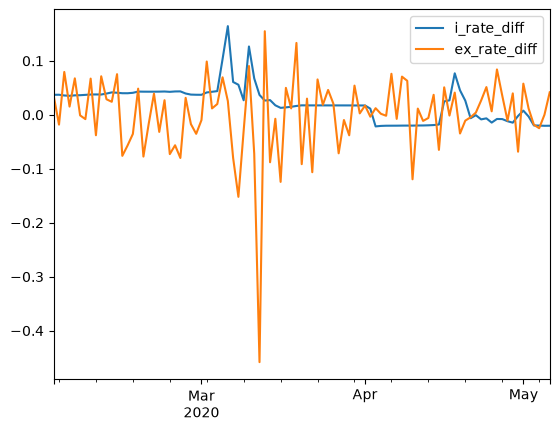

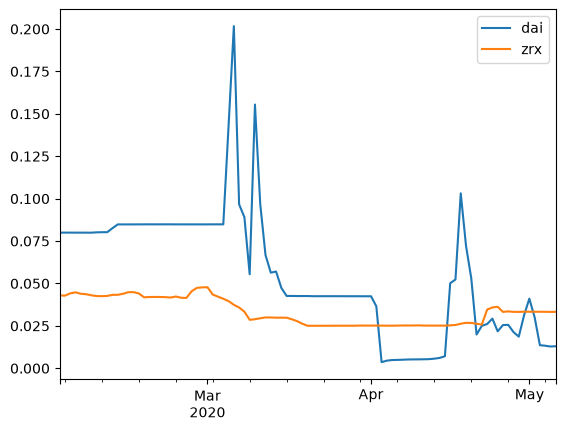

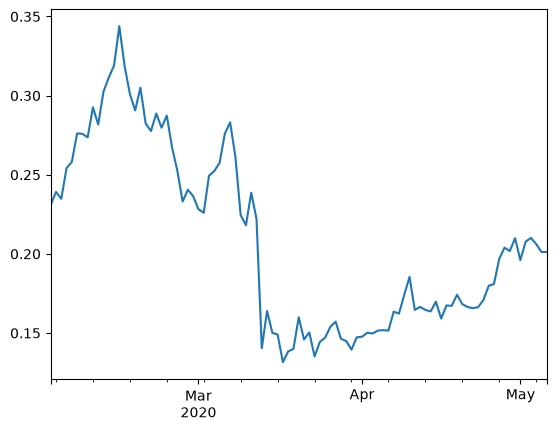

UIP does not hold.
Plot; base token: zrx, Quote token: sai


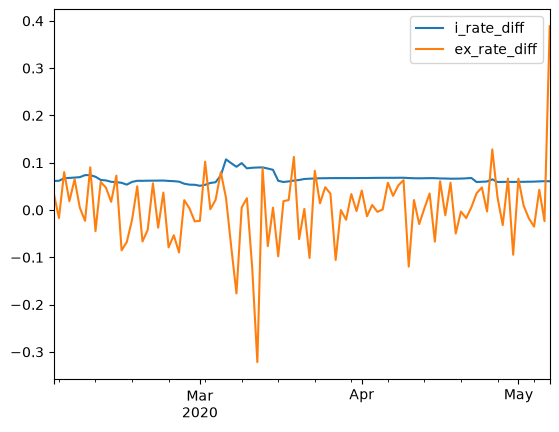

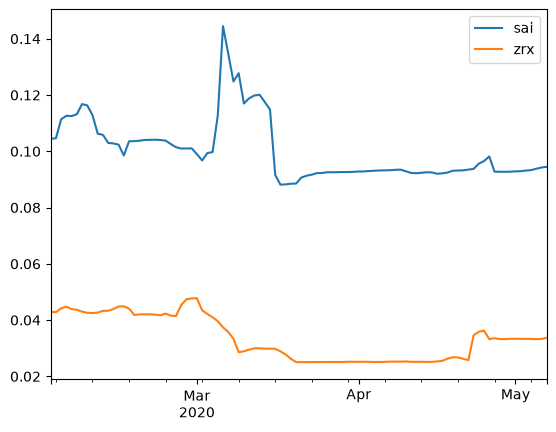

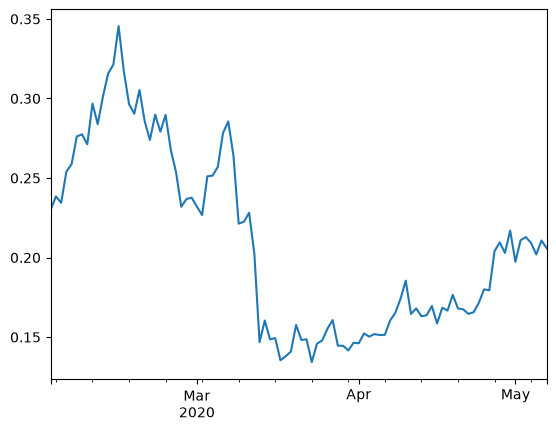

UIP does not hold.
Plot; base token: zrx, Quote token: rep


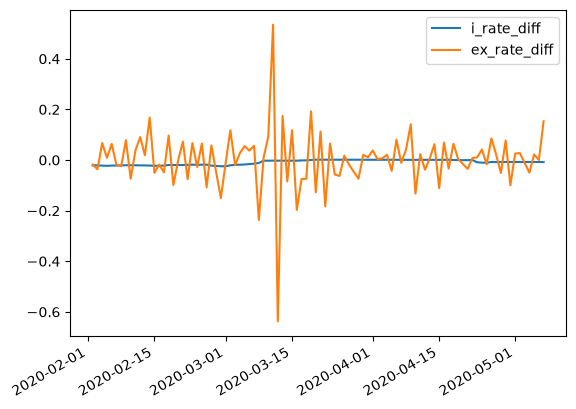

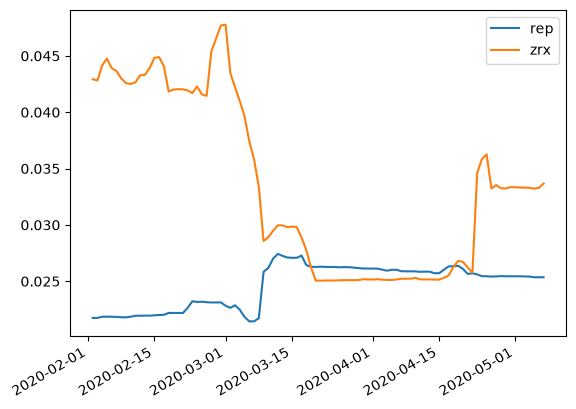

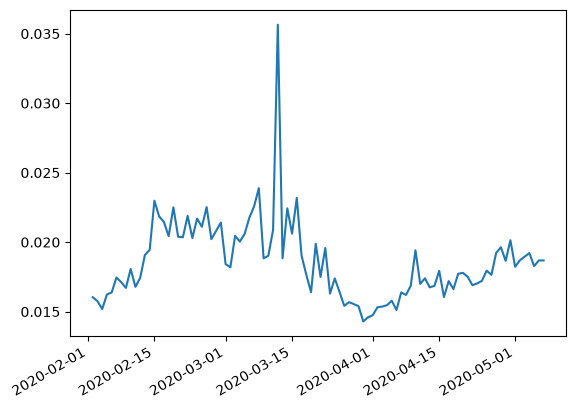

UIP does not hold.
Plot; base token: usdc, Quote token: dai


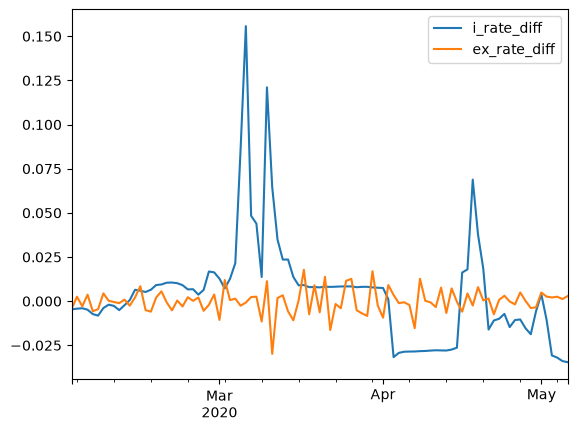

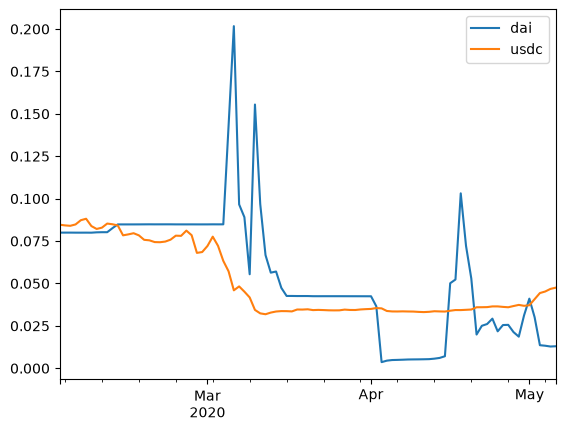

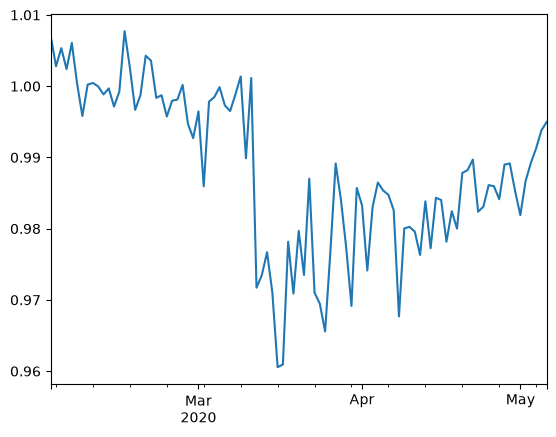

UIP does not hold.
Plot; base token: usdc, Quote token: sai


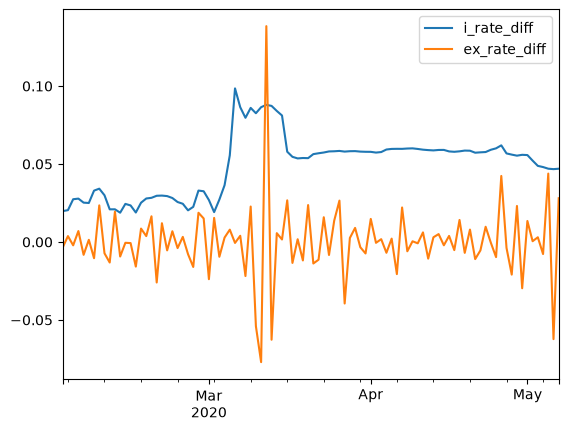

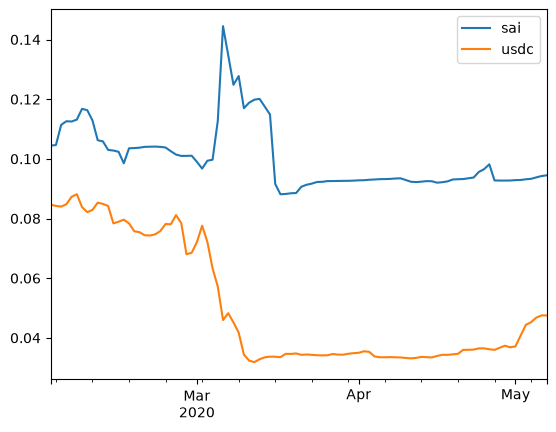

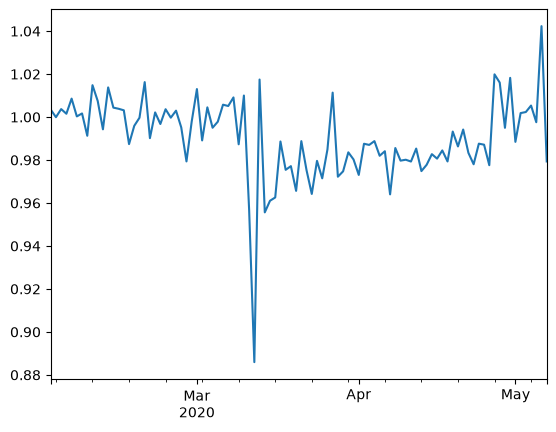

UIP does not hold.
Plot; base token: usdc, Quote token: rep


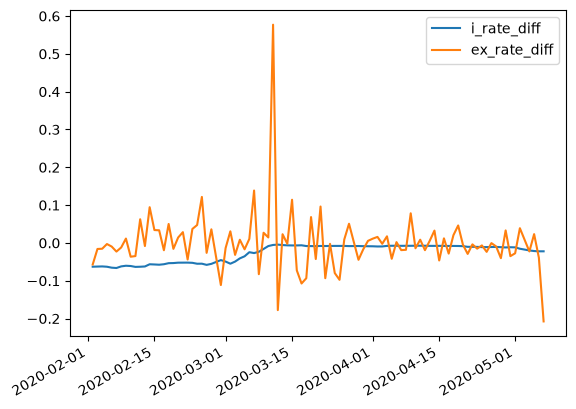

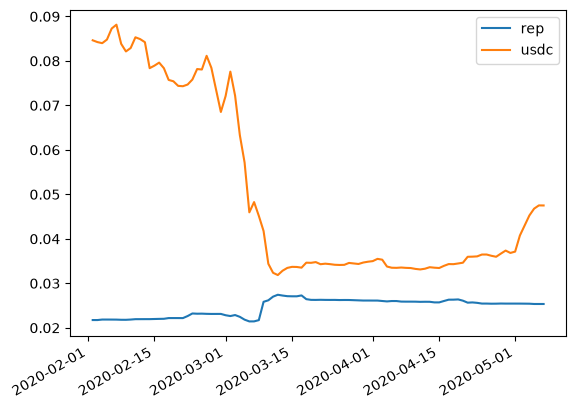

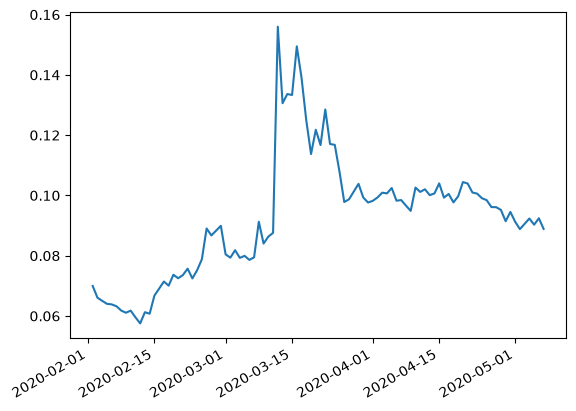

UIP does not hold.
Plot; base token: dai, Quote token: sai


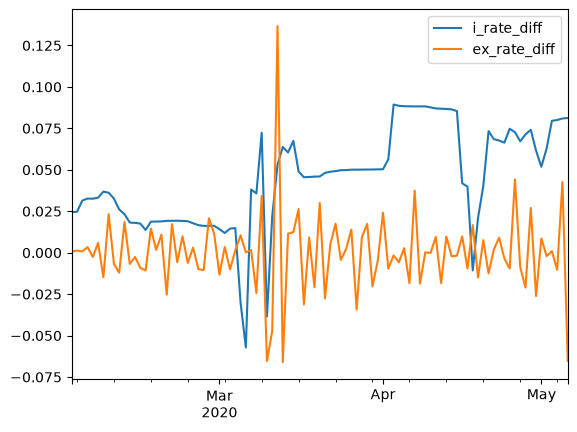

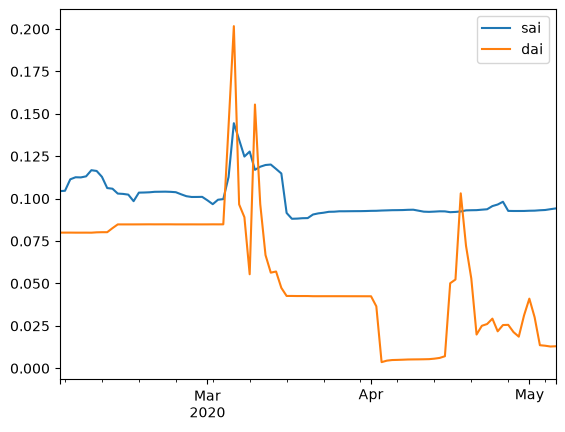

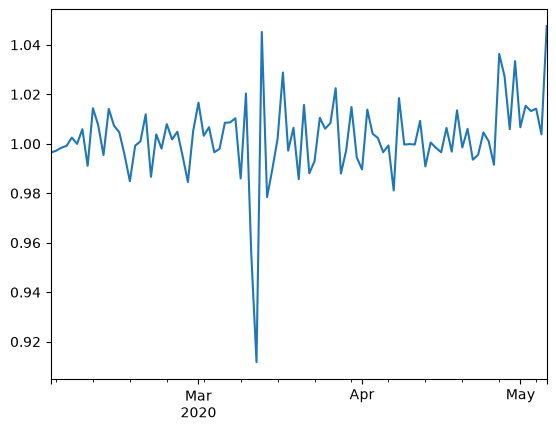

UIP does not hold.
Plot; base token: dai, Quote token: rep


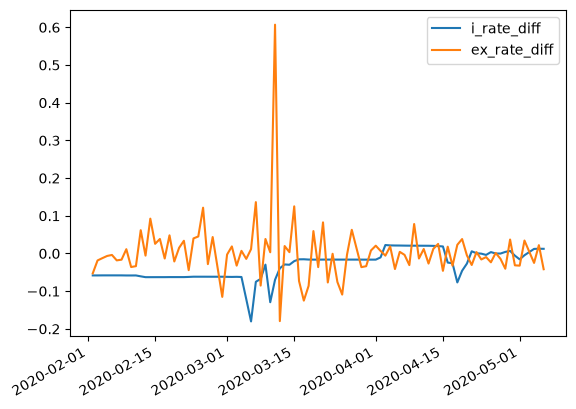

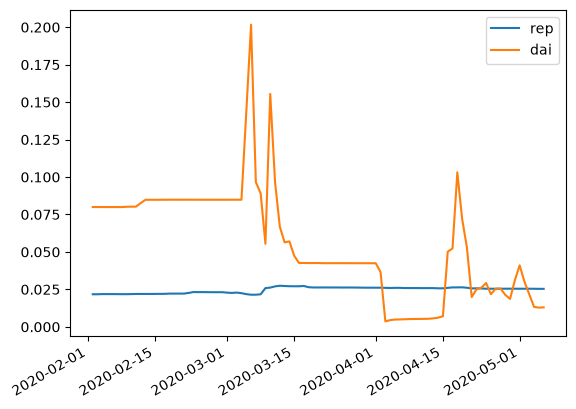

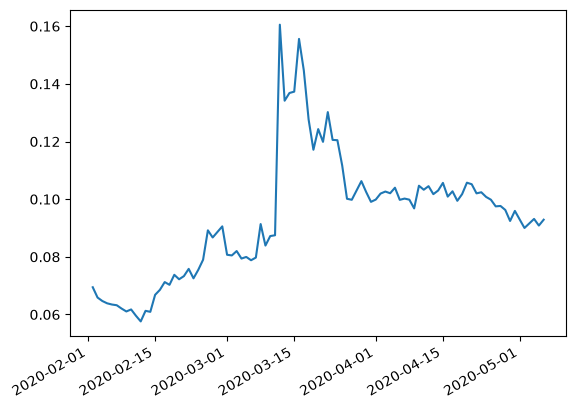

UIP does not hold.
UIP holds: {'eth_rep': np.float64(0.5990119431522685)}
UIP does not hold: {'eth_bat': np.float64(8.626554811947178e-07), 'eth_zrx': np.float64(0.00047393245160914146), 'eth_usdc': np.float64(3.519284794671479e-07), 'eth_dai': np.float64(5.11273593463995e-10), 'eth_sai': np.float64(4.011463721221856e-23), 'bat_zrx': np.float64(4.911900692469145e-07), 'bat_usdc': np.float64(0.0001188501809419349), 'bat_dai': np.float64(9.937959870477121e-14), 'bat_sai': np.float64(2.6066378653323885e-18), 'bat_rep': np.float64(0.001231174768811915), 'zrx_usdc': np.float64(0.026630995486846894), 'zrx_dai': np.float64(1.3808353180878835e-09), 'zrx_sai': np.float64(1.0497351976402217e-15), 'zrx_rep': np.float64(0.0067349430883420144), 'usdc_dai': np.float64(3.281079313253926e-76), 'usdc_sai': np.float64(1.014797869904997e-69), 'usdc_rep': np.float64(1.2847833960462457e-09), 'dai_sai': np.float64(3.1560345702147066e-57), 'dai_rep': np.float64(2.81148262065151e-10)}
\begin{tabular}{llllllll

In [17]:
## Daily, borrow
regression_runner(frequency='D', side='borrow')

Plot; base token: eth, Quote token: bat


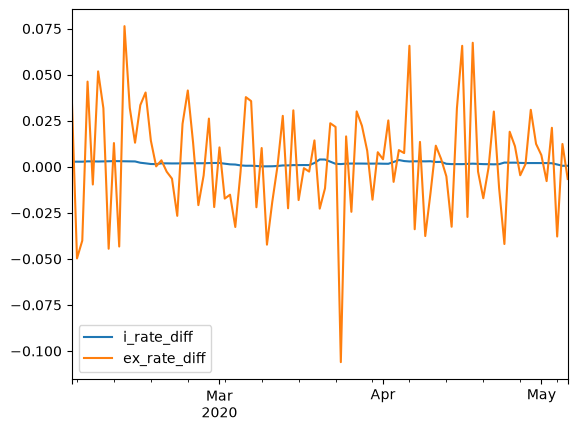

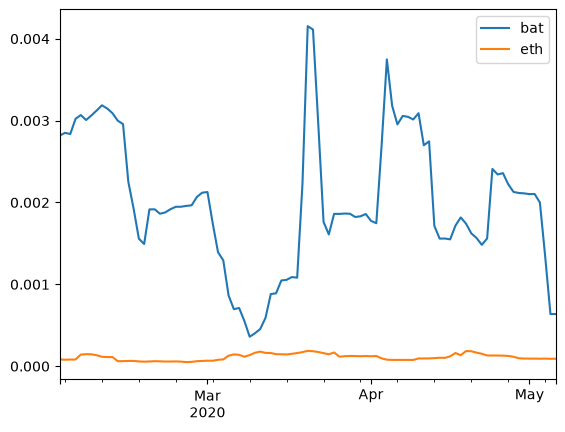

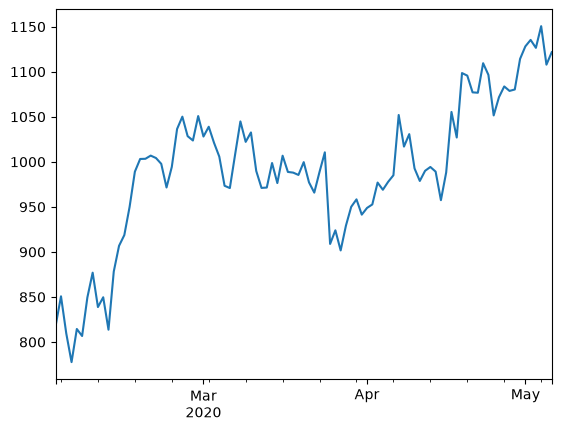

UIP holds.
Plot; base token: eth, Quote token: zrx


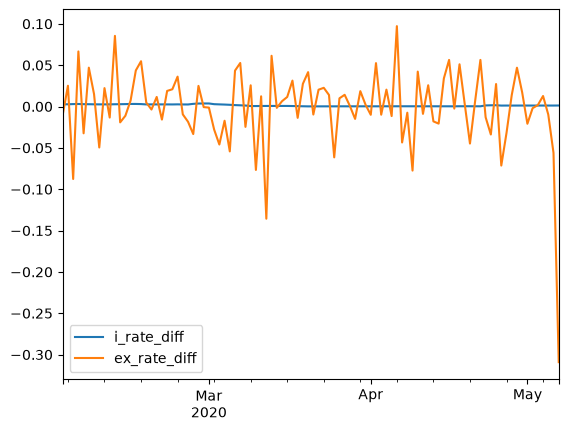

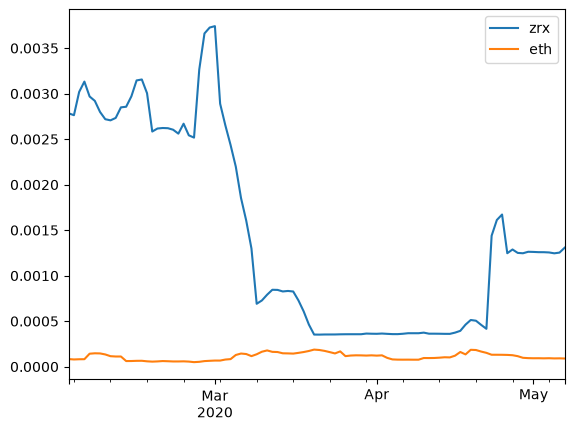

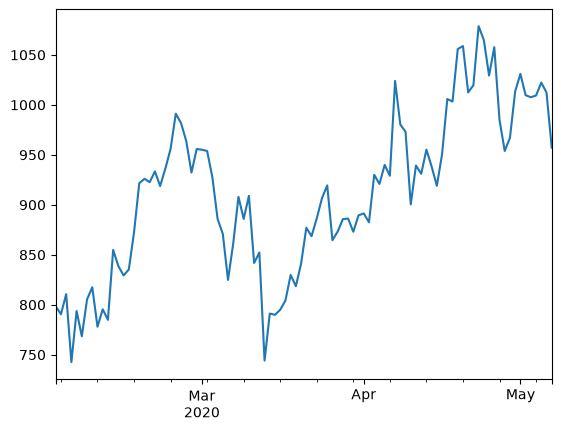

UIP holds.
              eth_usdc      usdc       eth
2020-02-01  179.284847  0.049004  0.000159
2020-02-02  183.096449  0.048590  0.000083
2020-02-03  188.504691  0.048063  0.000079
2020-02-04  189.334919  0.047746  0.000081
2020-02-05  188.327844  0.048814  0.000082
...                ...       ...       ...
2020-05-04  210.007876  0.010300  0.000093
2020-05-05  206.936404  0.011295  0.000091
2020-05-06  204.675484  0.011776  0.000091
2020-05-07  201.167493  0.011776  0.000090
2020-05-08  211.831291  0.012501  0.000091

[98 rows x 3 columns]
Plot; base token: eth, Quote token: usdc


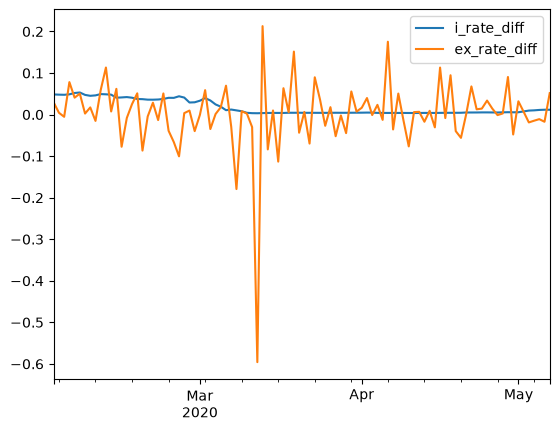

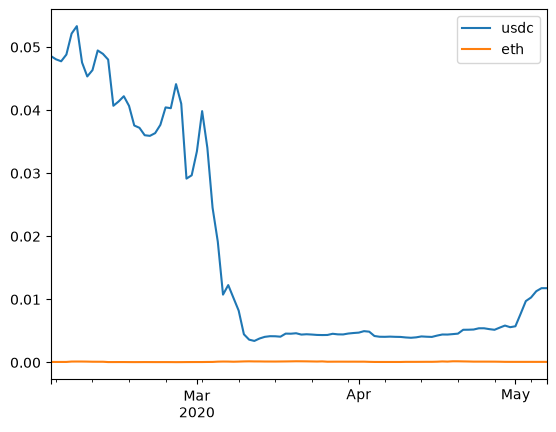

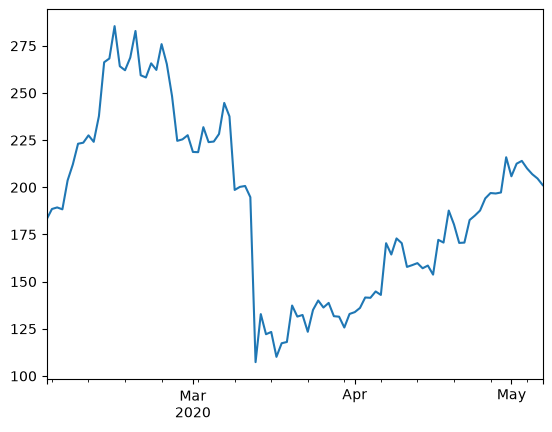

UIP does not hold.
Plot; base token: eth, Quote token: dai


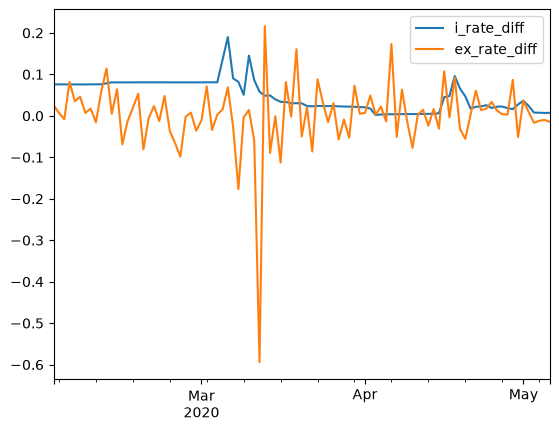

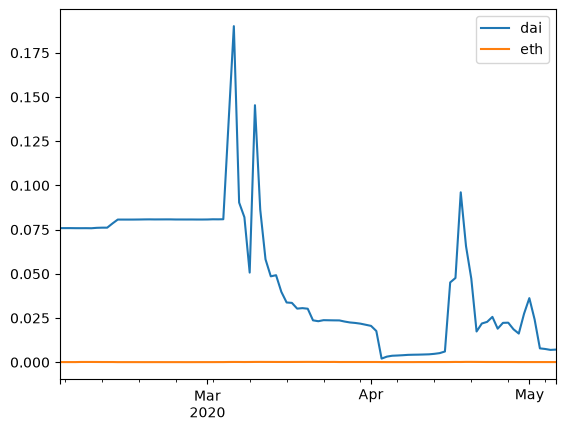

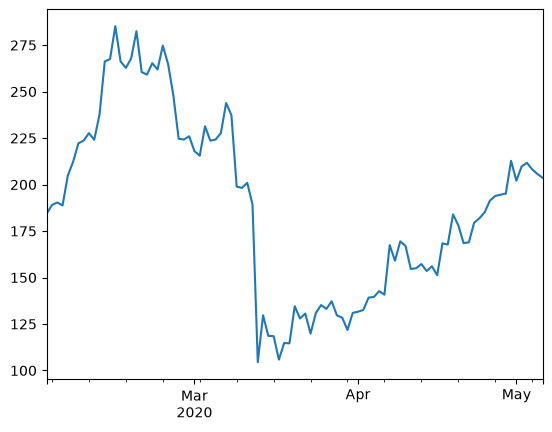

UIP does not hold.
Plot; base token: eth, Quote token: sai


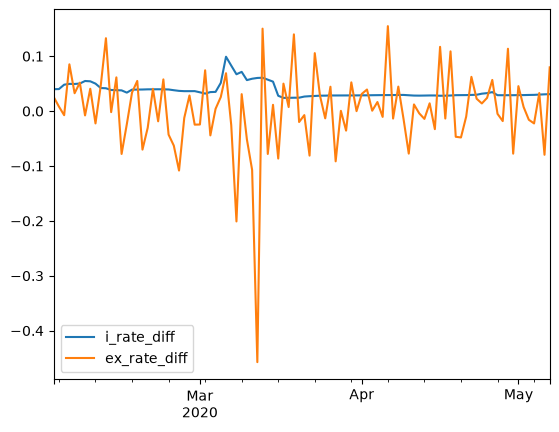

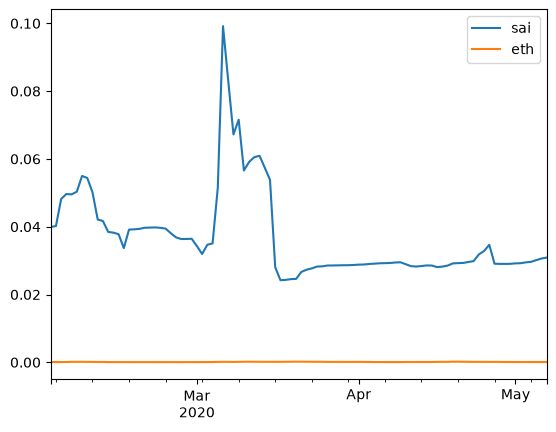

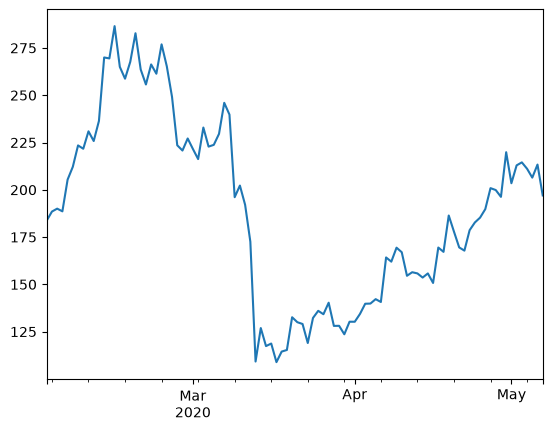

UIP does not hold.
Plot; base token: eth, Quote token: rep


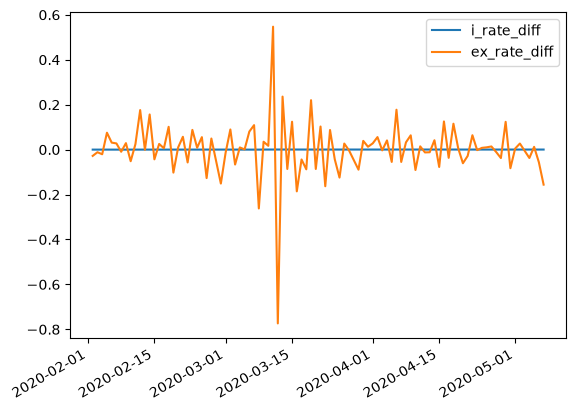

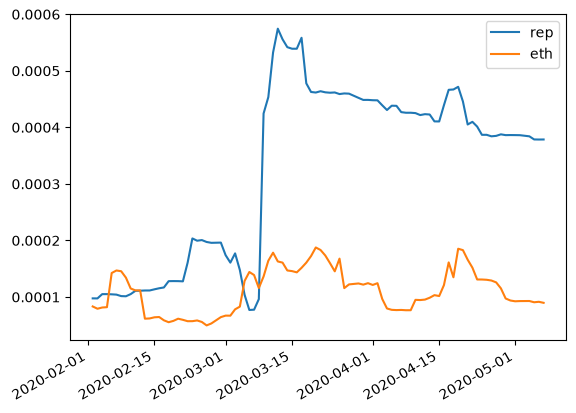

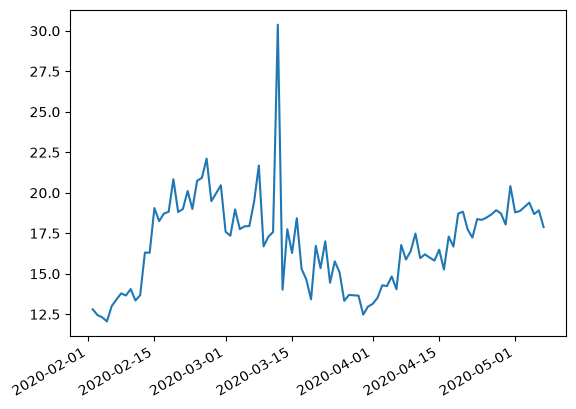

UIP holds.
Plot; base token: bat, Quote token: zrx


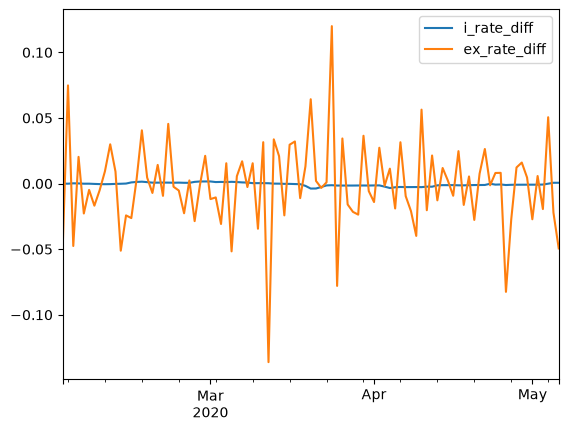

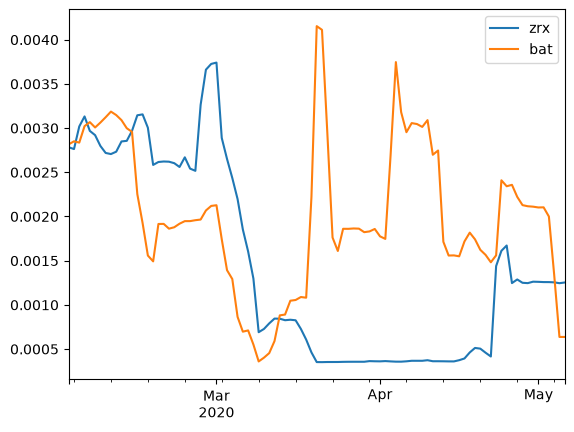

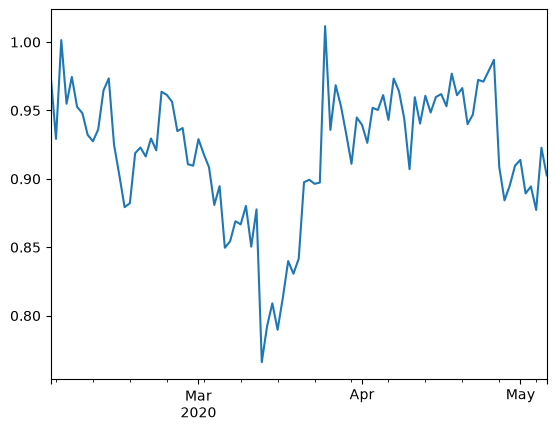

UIP holds.
Plot; base token: bat, Quote token: usdc


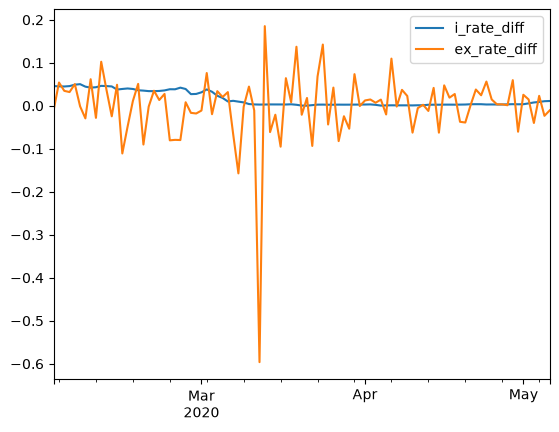

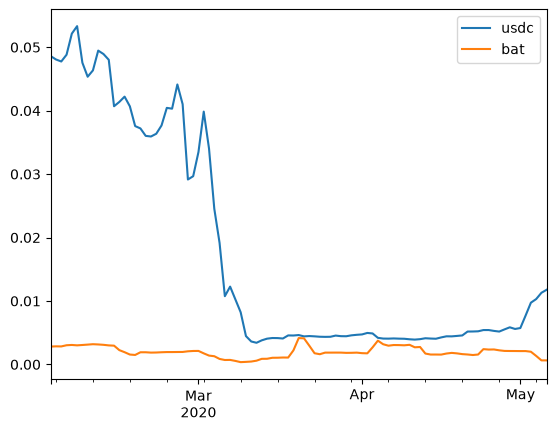

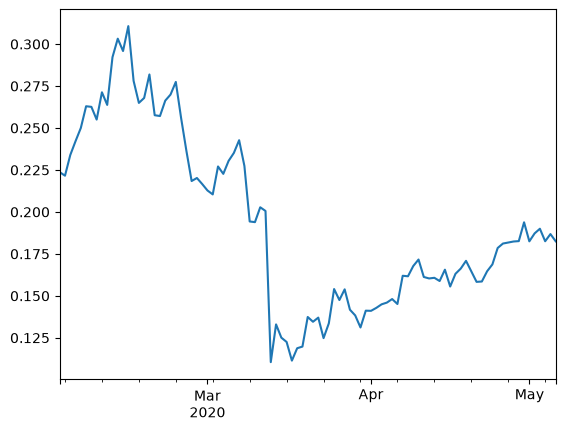

UIP does not hold.
Plot; base token: bat, Quote token: dai


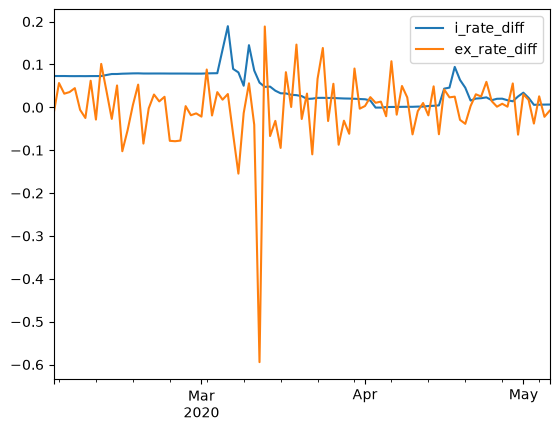

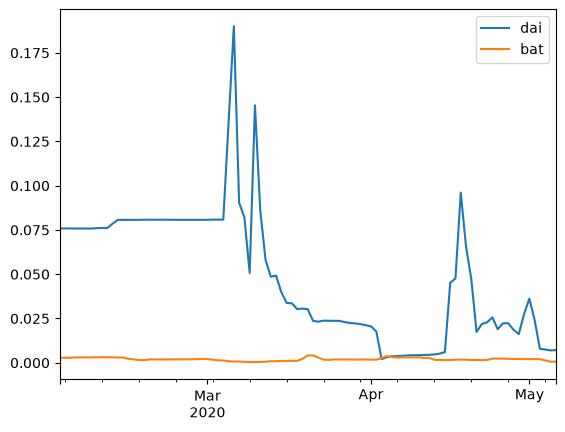

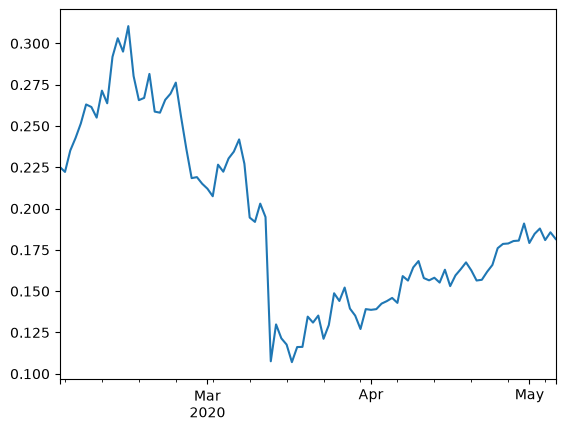

UIP does not hold.
Plot; base token: bat, Quote token: sai


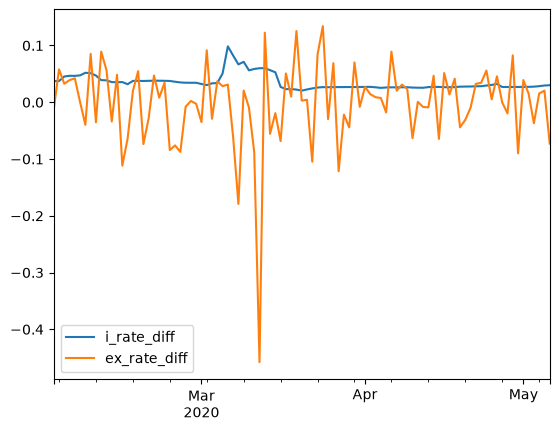

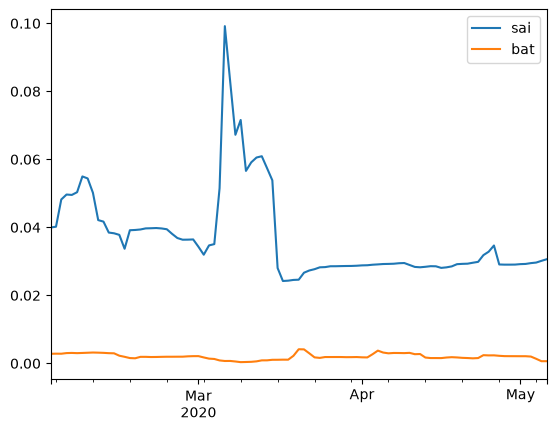

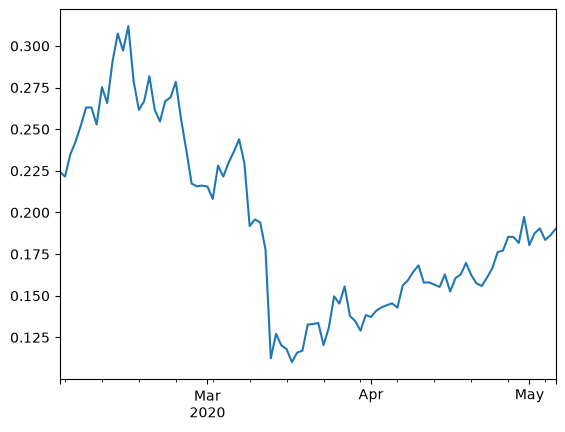

UIP does not hold.
Plot; base token: bat, Quote token: rep


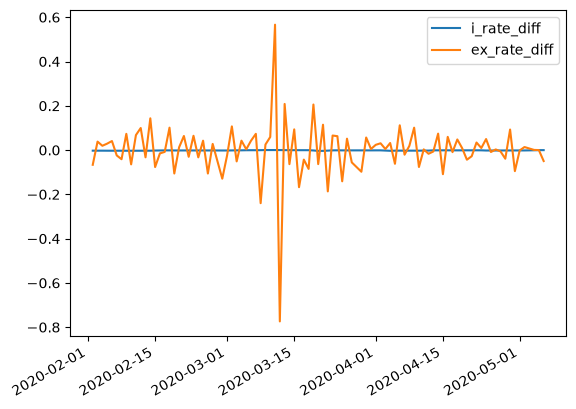

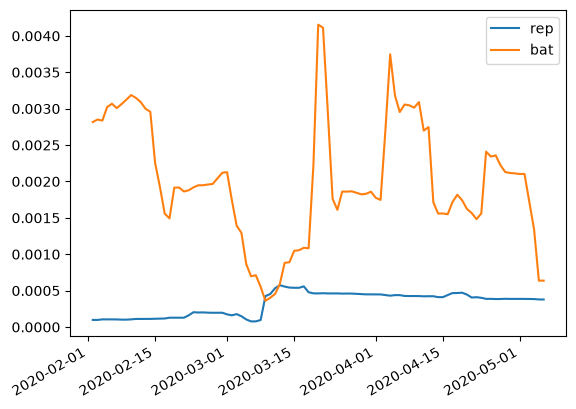

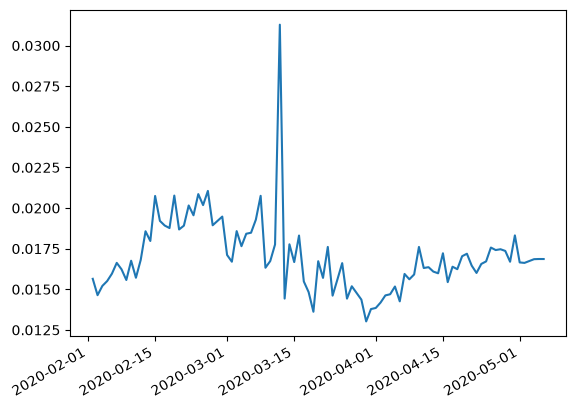

UIP holds.
Plot; base token: zrx, Quote token: usdc


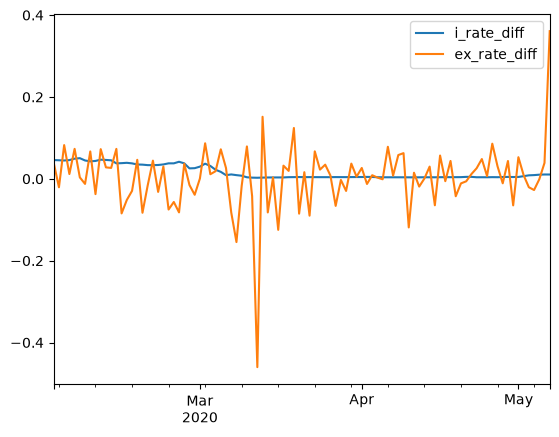

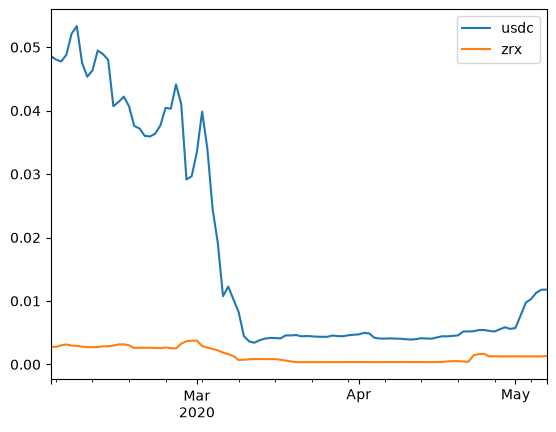

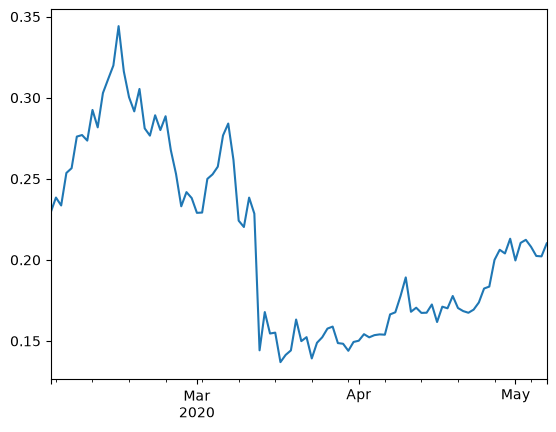

UIP does not hold.
Plot; base token: zrx, Quote token: dai


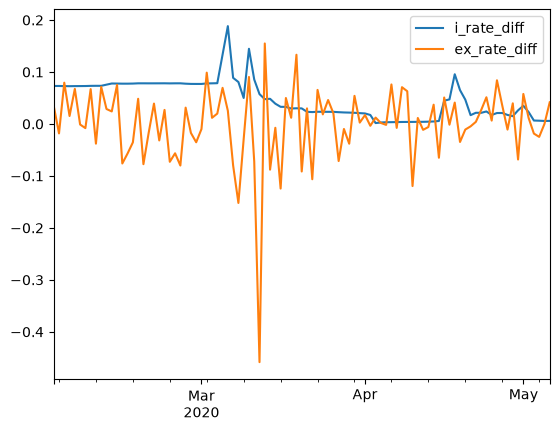

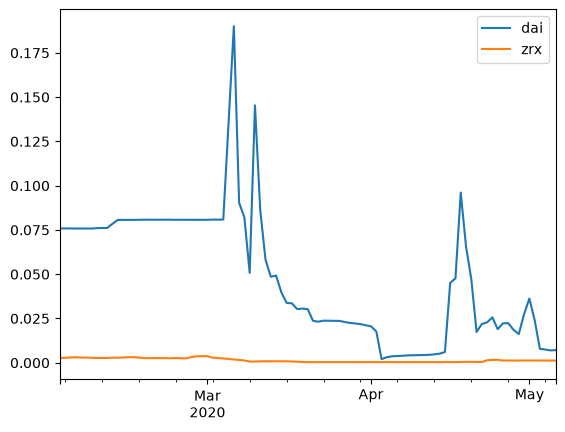

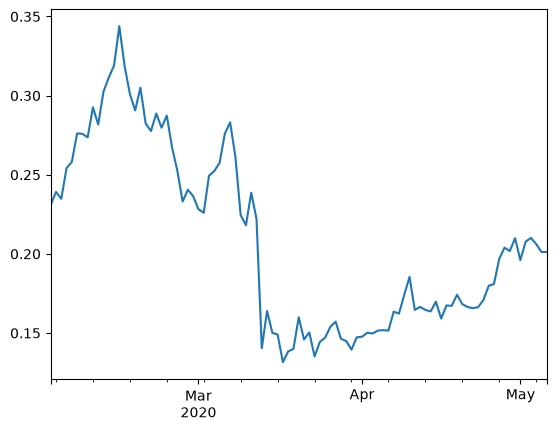

UIP does not hold.
Plot; base token: zrx, Quote token: sai


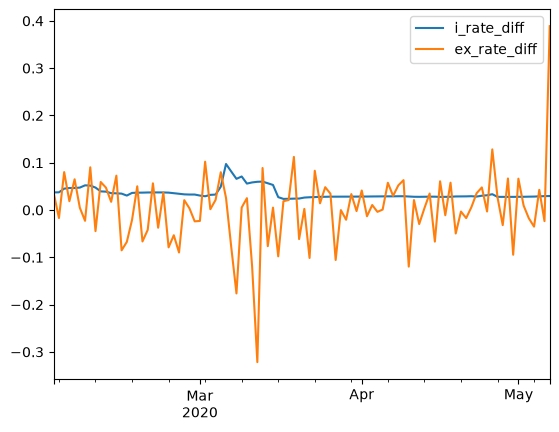

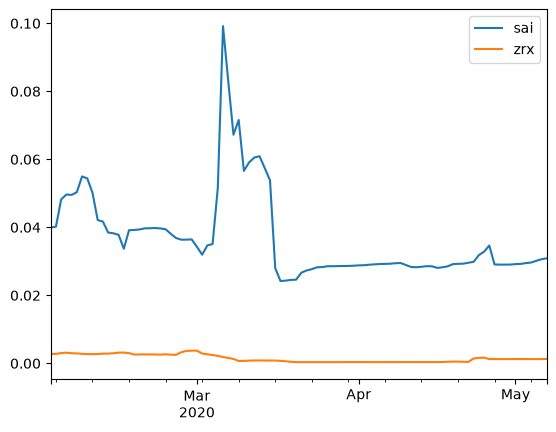

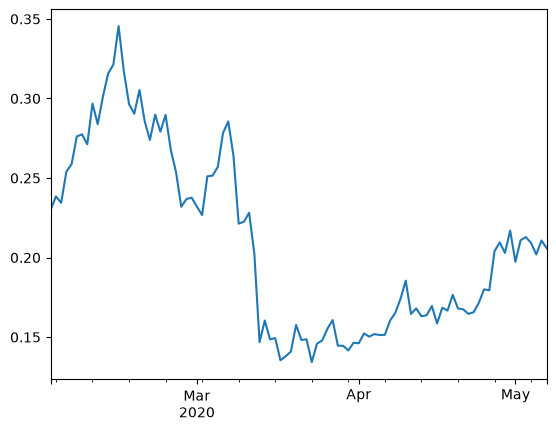

UIP does not hold.
Plot; base token: zrx, Quote token: rep


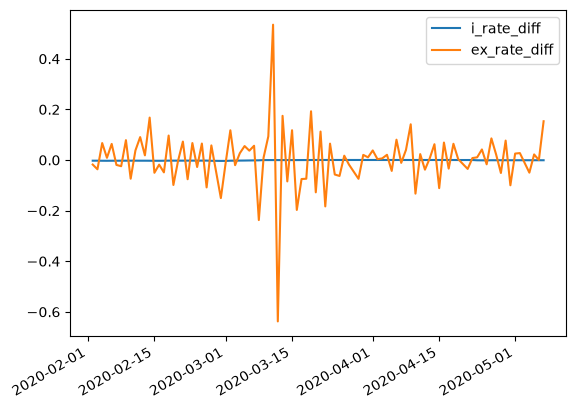

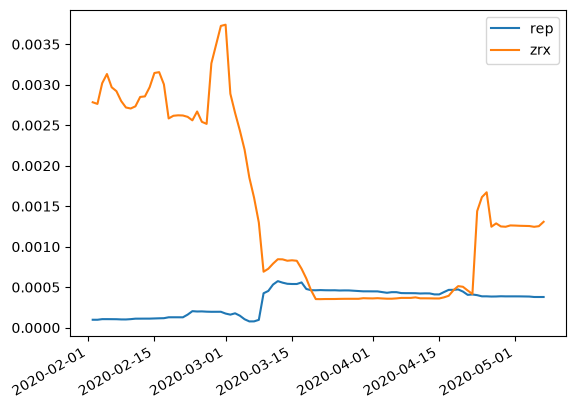

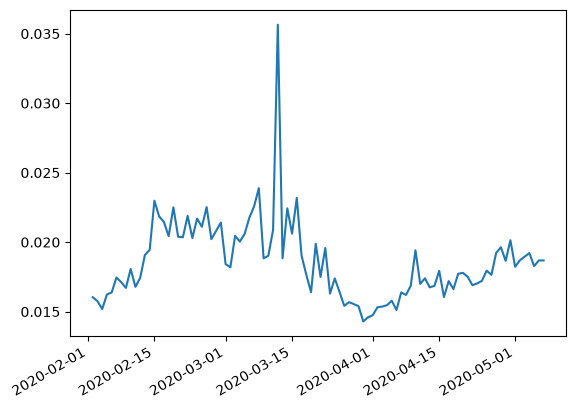

UIP holds.
Plot; base token: usdc, Quote token: dai


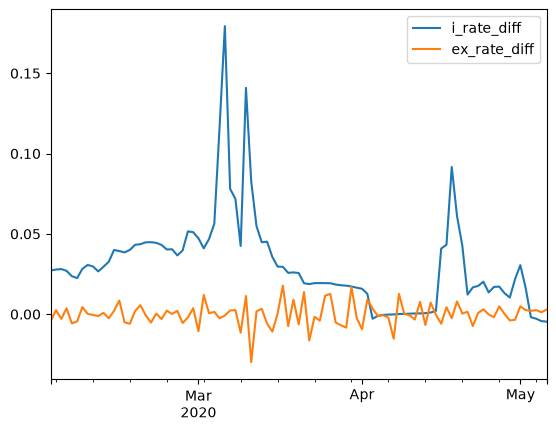

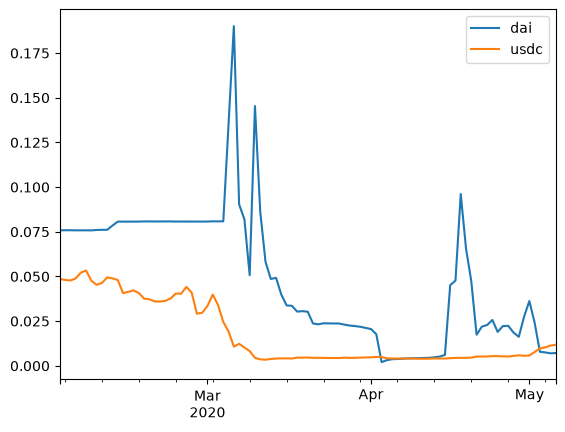

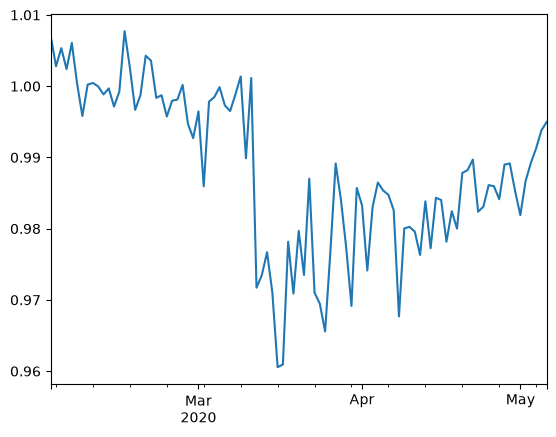

UIP does not hold.
Plot; base token: usdc, Quote token: sai


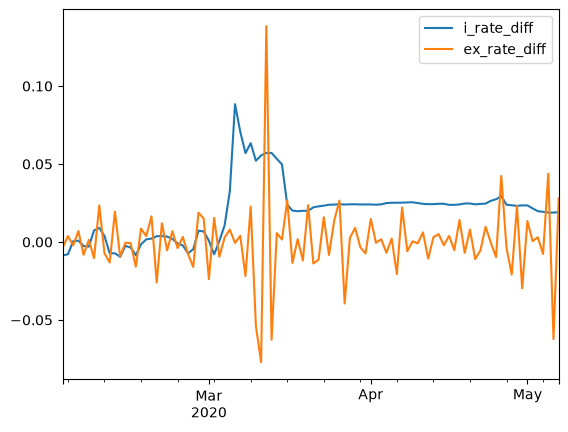

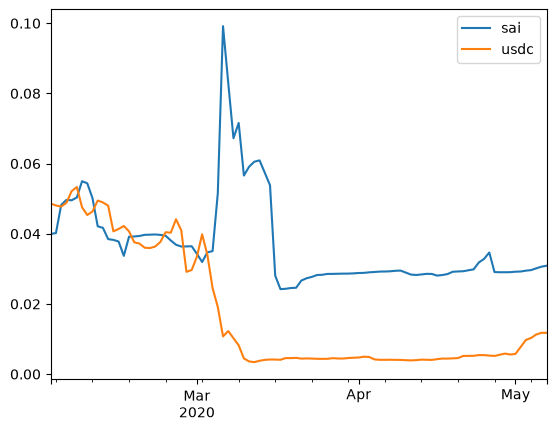

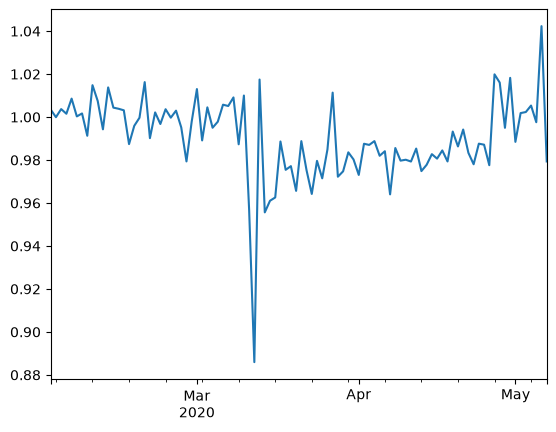

UIP does not hold.
Plot; base token: usdc, Quote token: rep


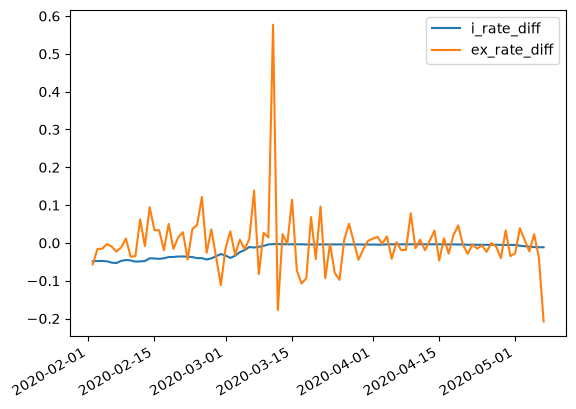

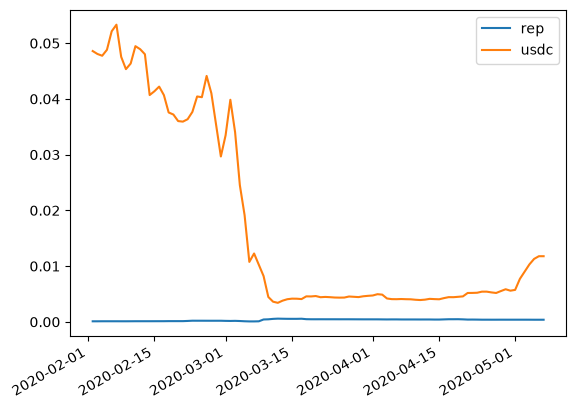

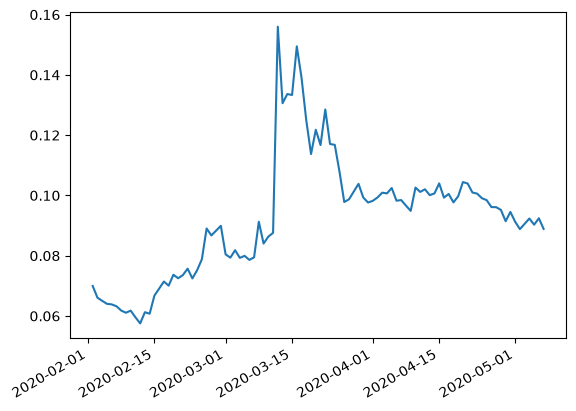

UIP does not hold.
Plot; base token: dai, Quote token: sai


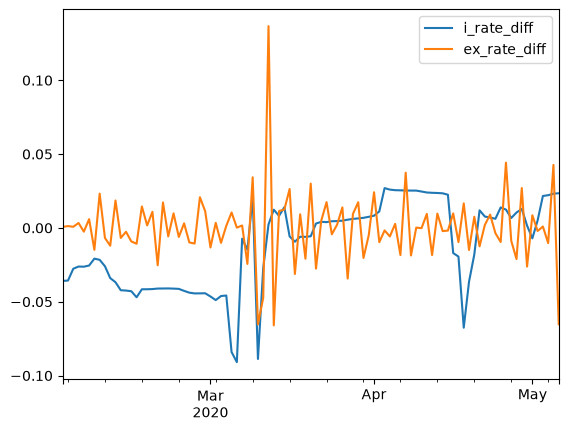

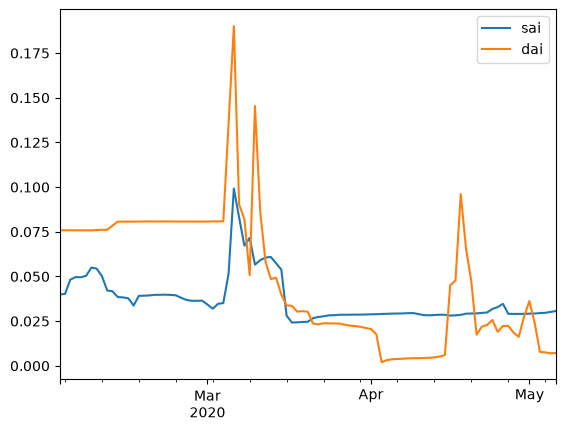

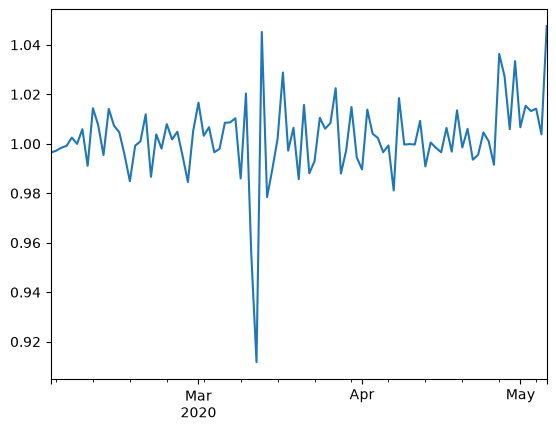

UIP does not hold.
Plot; base token: dai, Quote token: rep


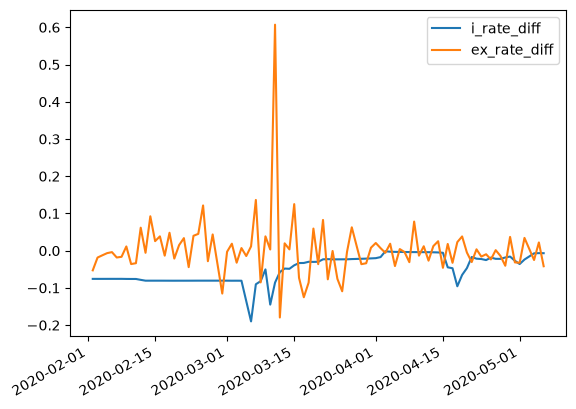

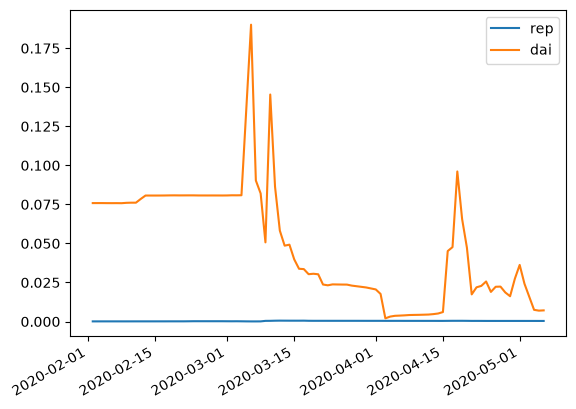

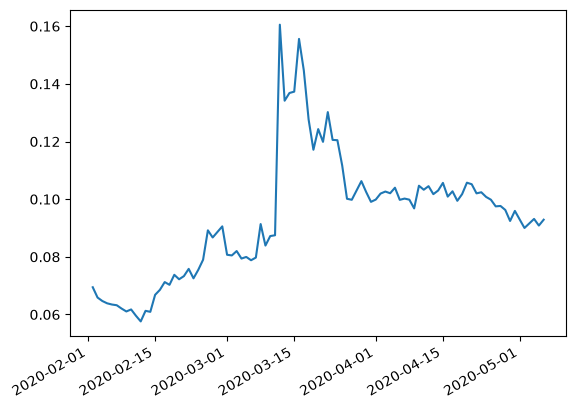

UIP does not hold.
UIP holds: {'eth_bat': np.float64(0.8252954729628244), 'eth_zrx': np.float64(0.7463200497741037), 'eth_rep': np.float64(0.5556433134366121), 'bat_zrx': np.float64(0.09218397810164476), 'bat_rep': np.float64(0.4062486053879394), 'zrx_rep': np.float64(0.5061416997494267)}
UIP does not hold: {'eth_usdc': np.float64(0.0016872521099094138), 'eth_dai': np.float64(5.653675554151122e-12), 'eth_sai': np.float64(2.3540116444016733e-06), 'bat_usdc': np.float64(0.0006239850821504977), 'bat_dai': np.float64(9.999842269537653e-16), 'bat_sai': np.float64(2.53570380630167e-07), 'zrx_usdc': np.float64(0.008301570510582222), 'zrx_dai': np.float64(1.6114529941109936e-14), 'zrx_sai': np.float64(7.503796152916728e-06), 'usdc_dai': np.float64(1.9112093450280247e-91), 'usdc_sai': np.float64(1.49515161259508e-28), 'usdc_rep': np.float64(2.2975857563090034e-06), 'dai_sai': np.float64(3.9973404686201446e-22), 'dai_rep': np.float64(1.4980988463867662e-12)}
\begin{tabular}{lllllllll}
\toprule
p

In [18]:
## Daily, supply
regression_runner(frequency='D', side='supply')

Plot; base token: eth, Quote token: bat


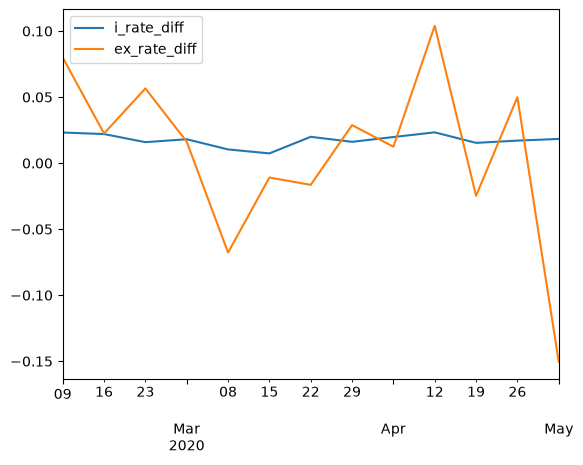

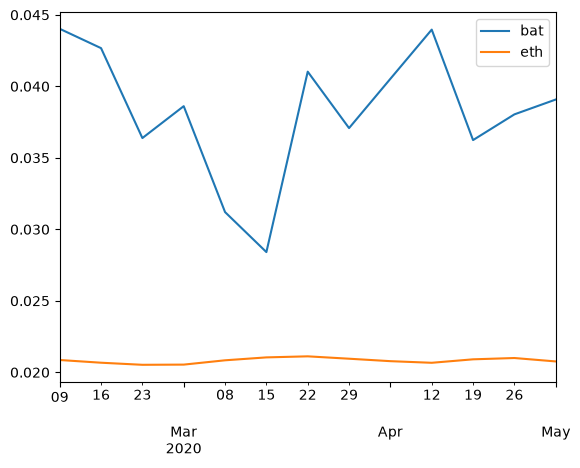

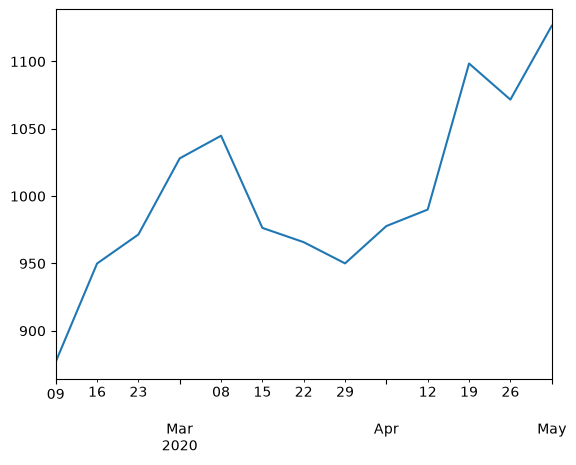

UIP holds.
Plot; base token: eth, Quote token: zrx


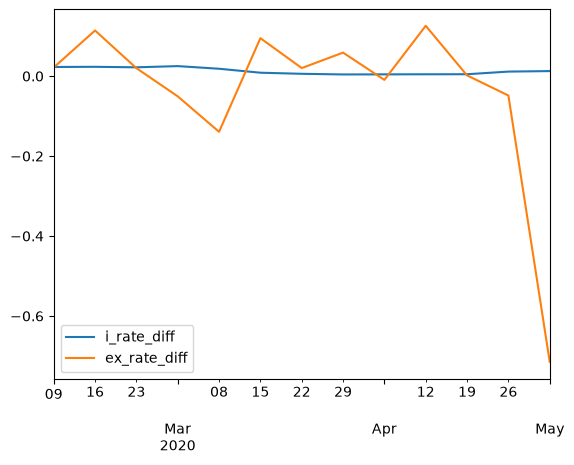

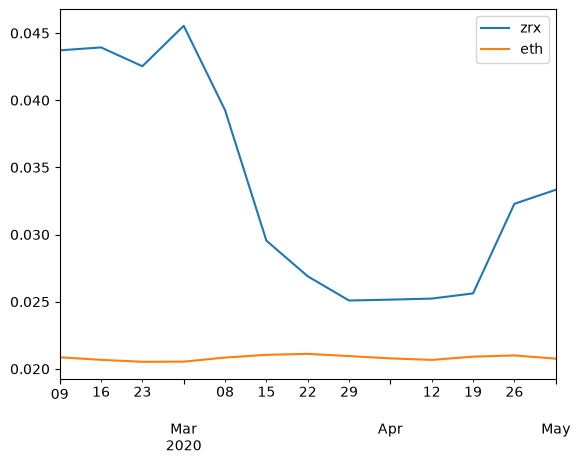

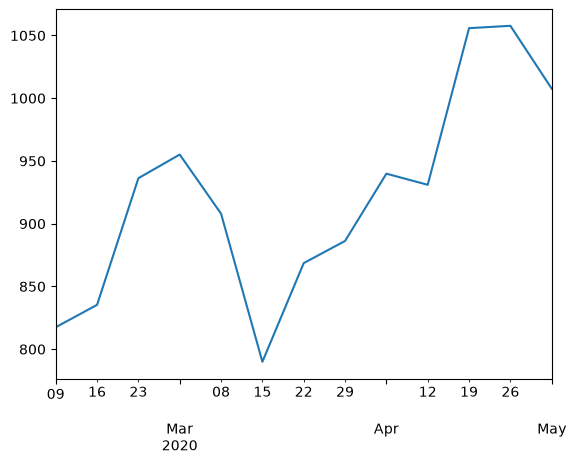

UIP holds.
              eth_usdc      usdc       eth
2020-02-02  183.096449  0.084435  0.020941
2020-02-09  223.645194  0.084943  0.020859
2020-02-16  264.172929  0.081933  0.020670
2020-02-23  262.217776  0.075745  0.020524
2020-03-01  218.740060  0.074877  0.020538
2020-03-08  237.585665  0.055326  0.020839
2020-03-15  122.127532  0.034802  0.021043
2020-03-22  132.332452  0.034266  0.021116
2020-03-29  131.417426  0.034301  0.020950
2020-04-05  144.795176  0.034657  0.020778
2020-04-12  158.756430  0.033378  0.020665
2020-04-19  187.672423  0.033956  0.020908
2020-04-26  194.139577  0.035953  0.020999
2020-05-03  214.003359  0.038387  0.020760
2020-05-10  210.842570  0.046822  0.020705
Plot; base token: eth, Quote token: usdc


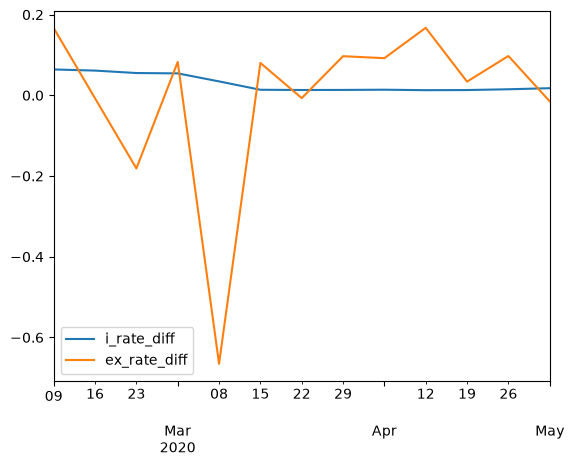

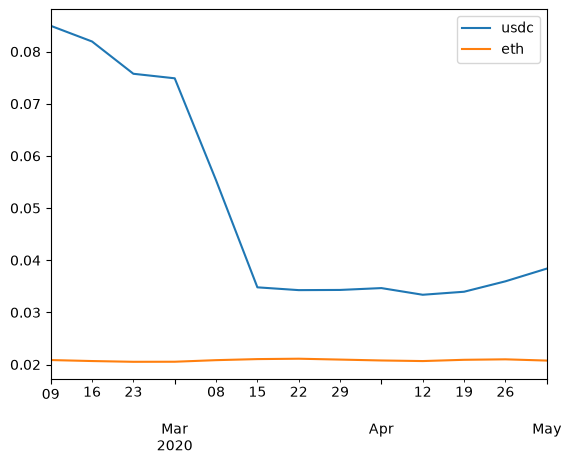

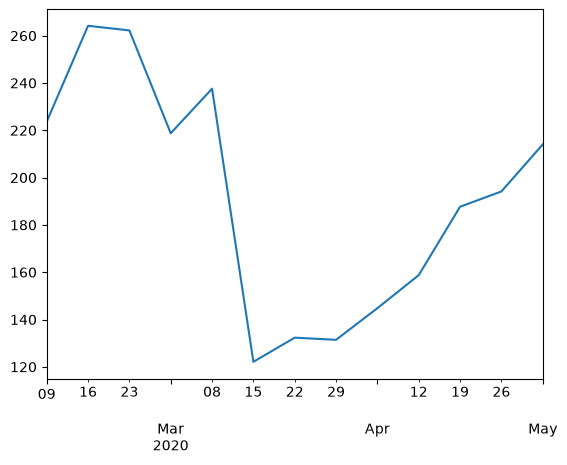

UIP holds.
Plot; base token: eth, Quote token: dai


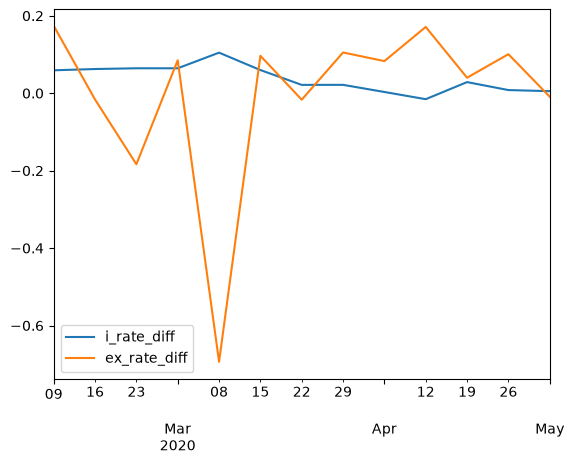

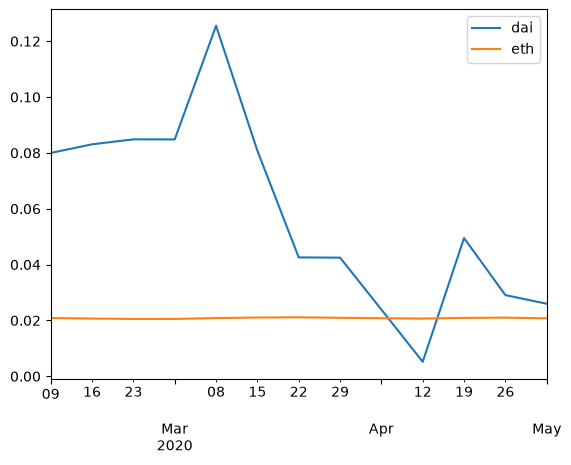

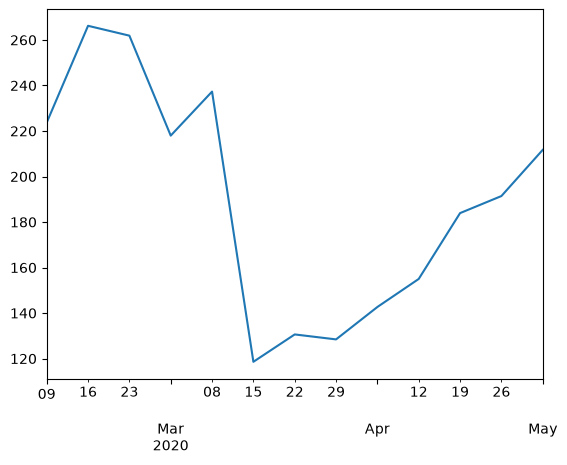

UIP does not hold.
Plot; base token: eth, Quote token: sai


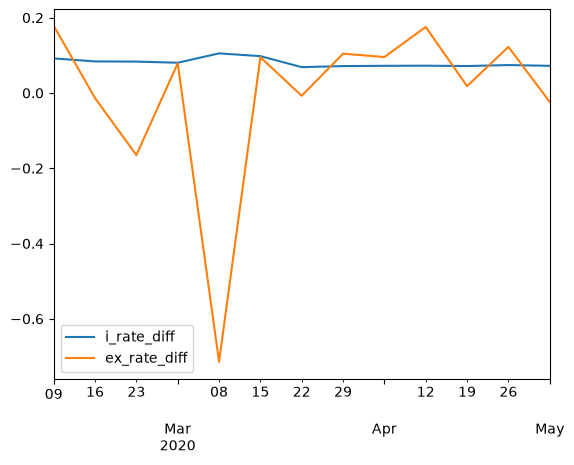

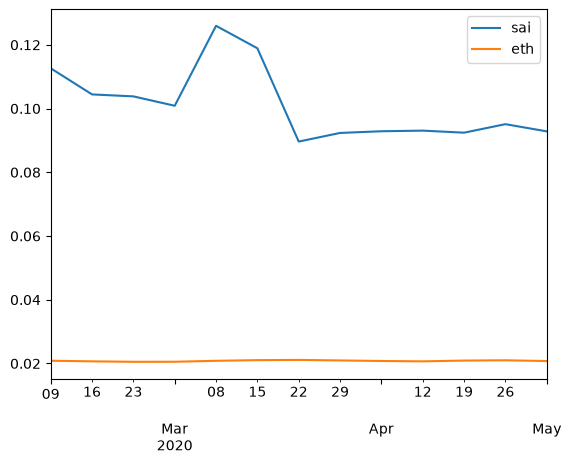

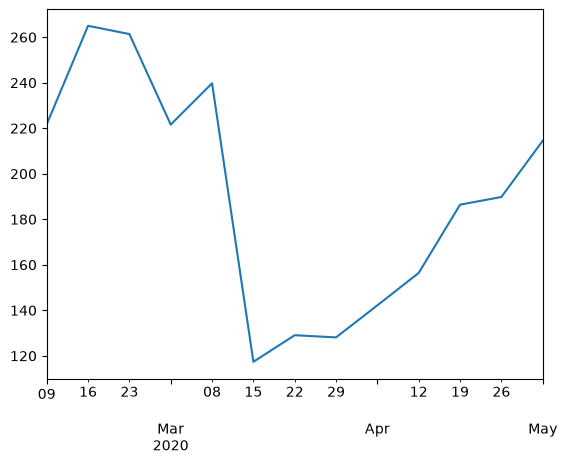

UIP holds.
Plot; base token: eth, Quote token: rep


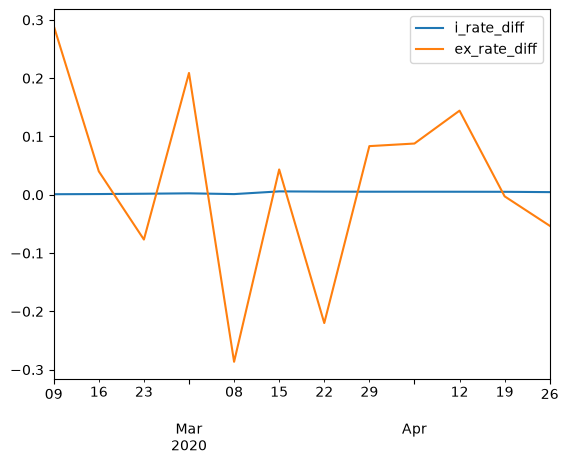

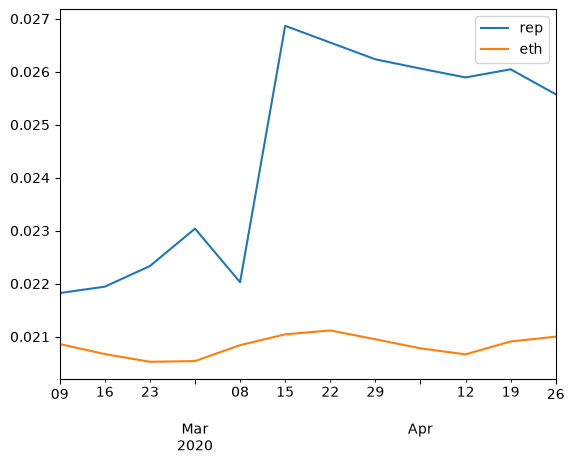

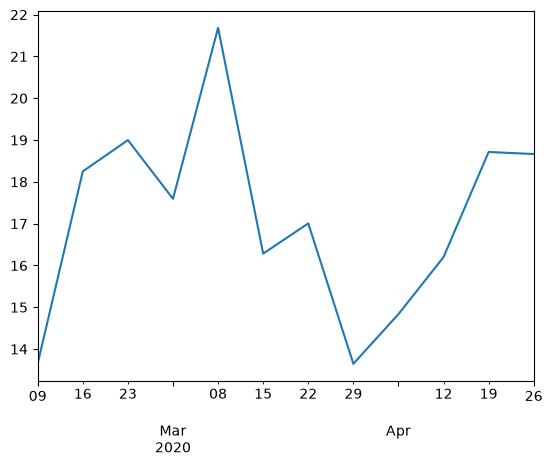

UIP holds.
Plot; base token: bat, Quote token: zrx


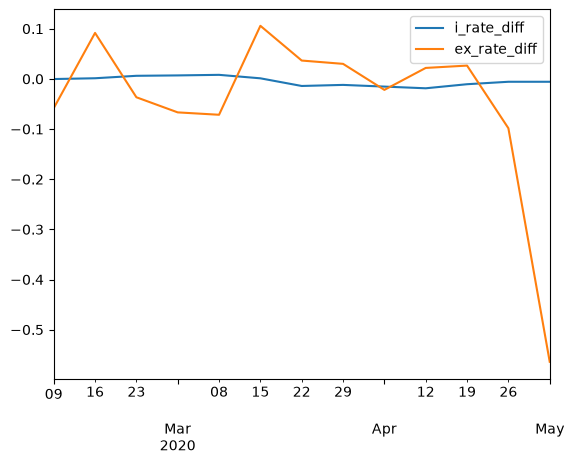

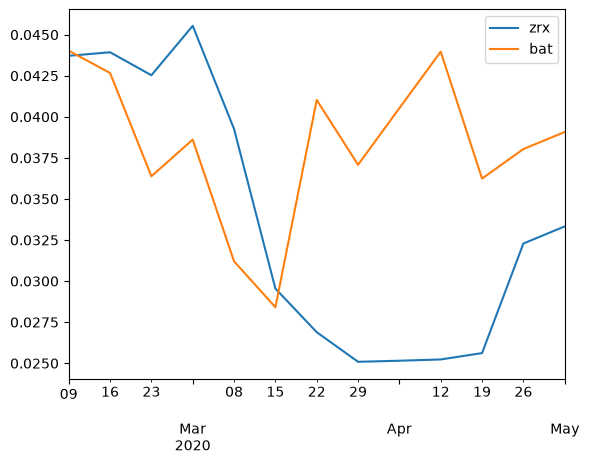

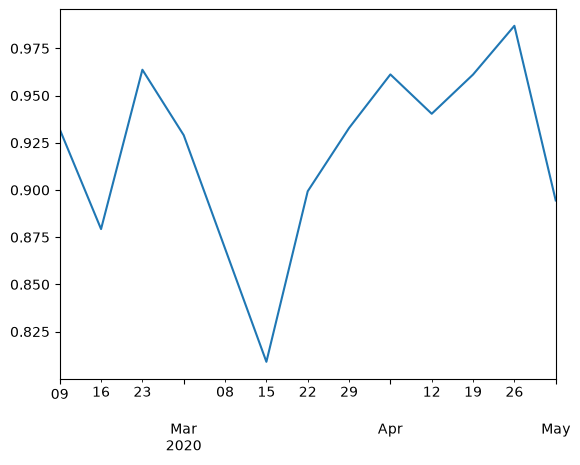

UIP holds.
Plot; base token: bat, Quote token: usdc


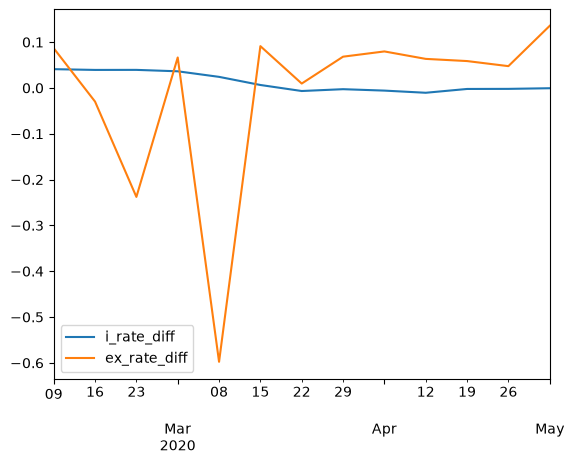

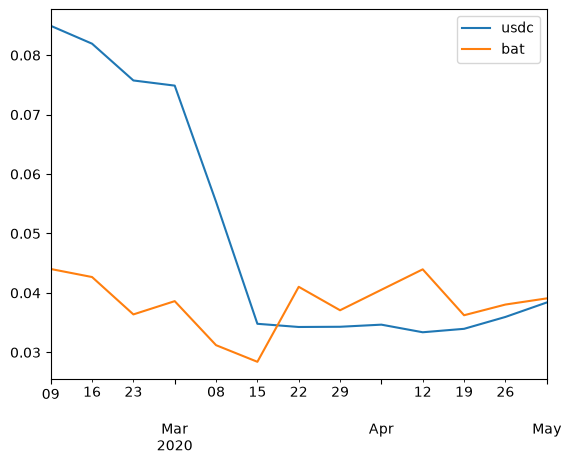

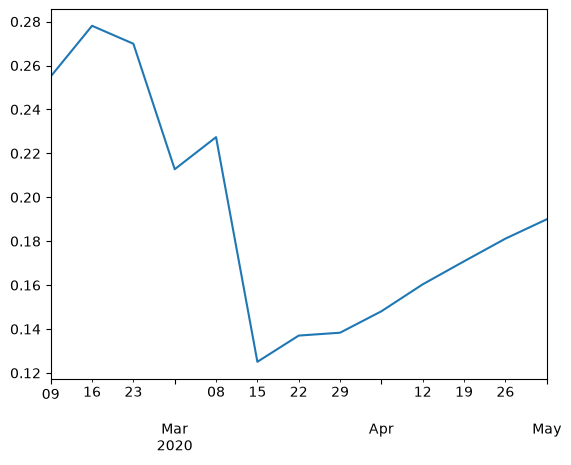

UIP does not hold.
Plot; base token: bat, Quote token: dai


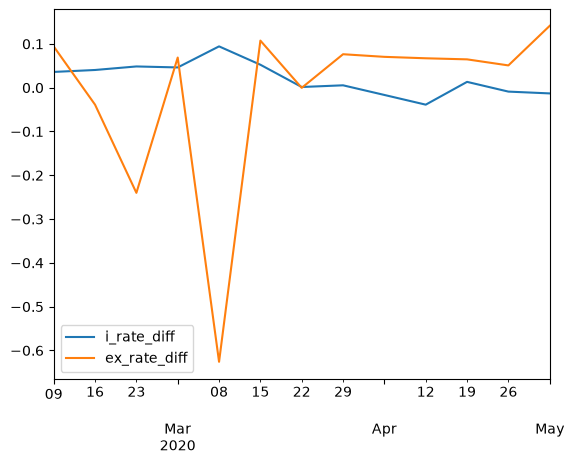

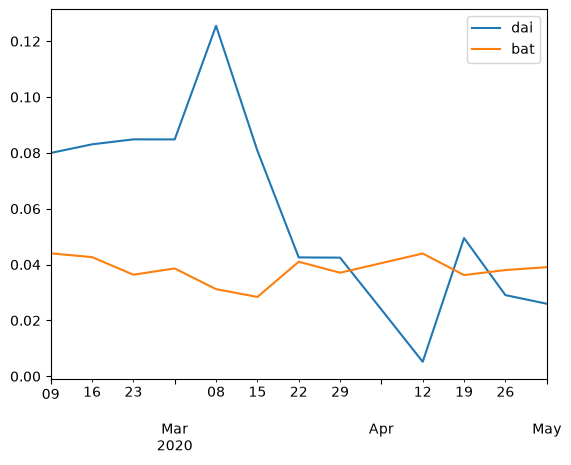

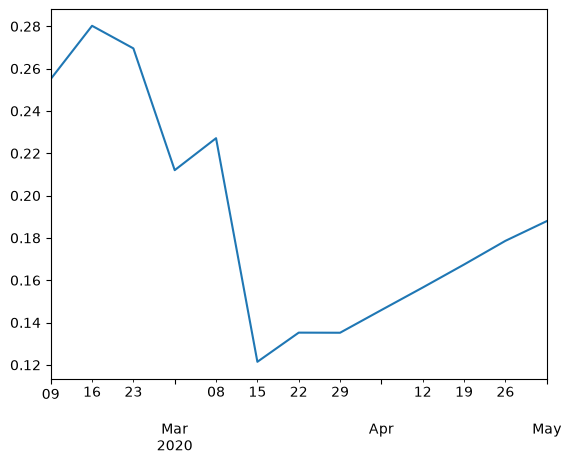

UIP does not hold.
Plot; base token: bat, Quote token: sai


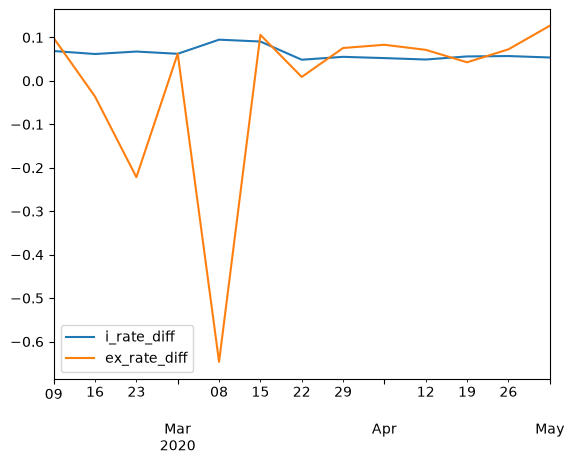

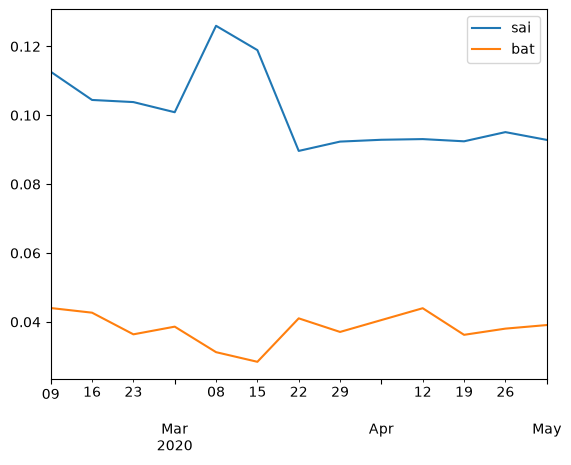

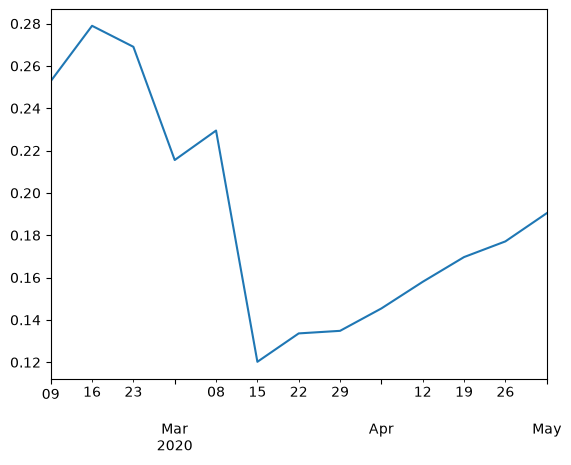

UIP holds.
Plot; base token: bat, Quote token: rep


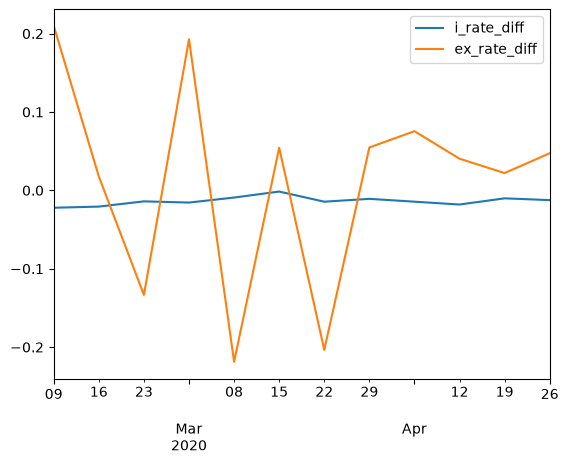

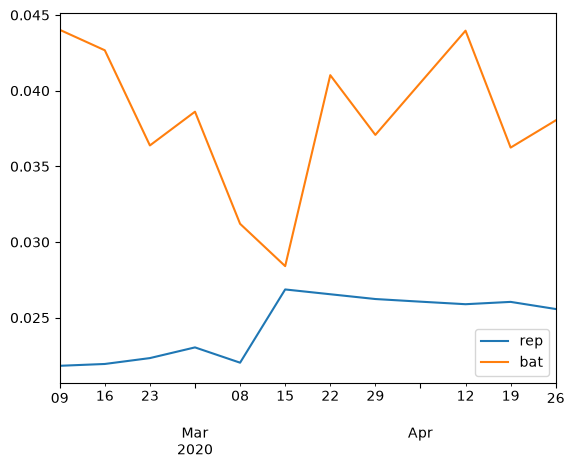

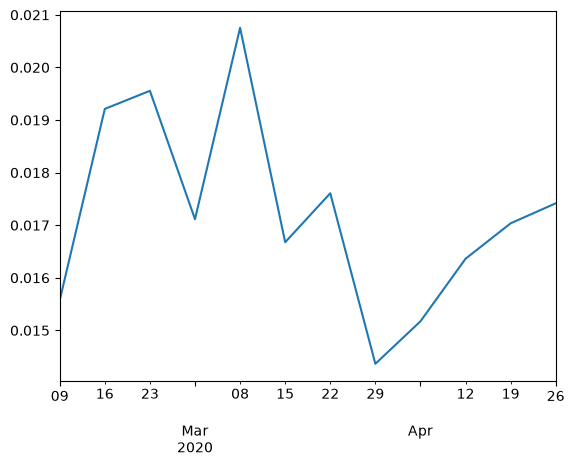

UIP holds.
Plot; base token: zrx, Quote token: usdc


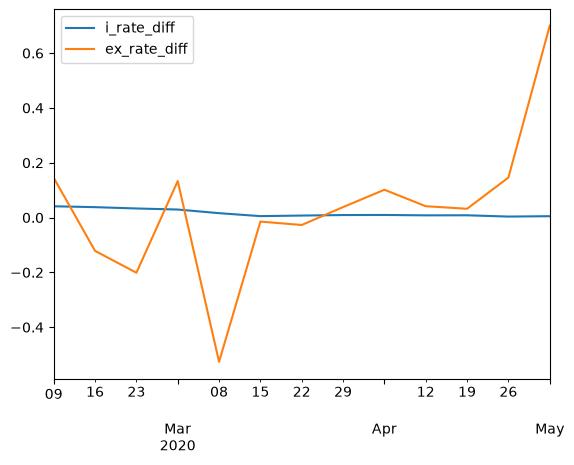

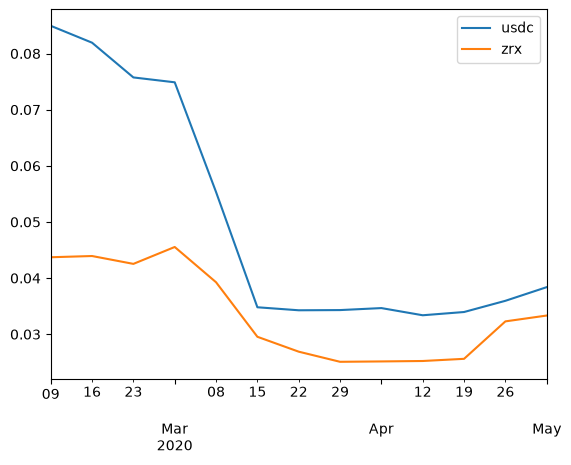

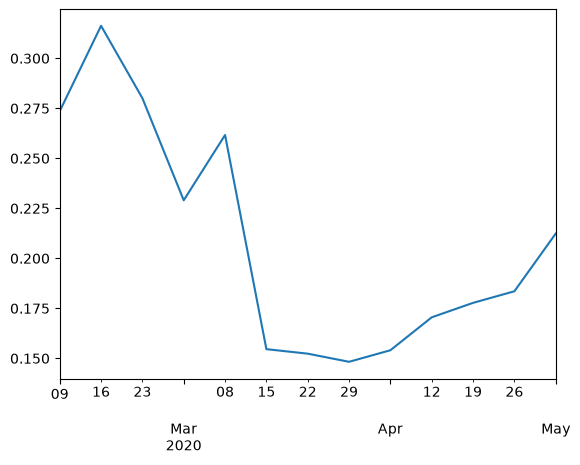

UIP holds.
Plot; base token: zrx, Quote token: dai


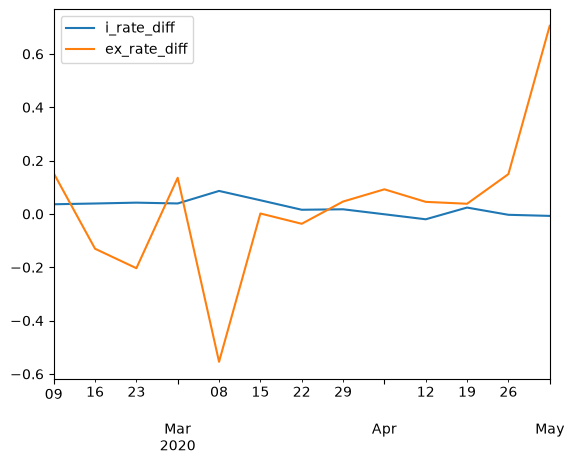

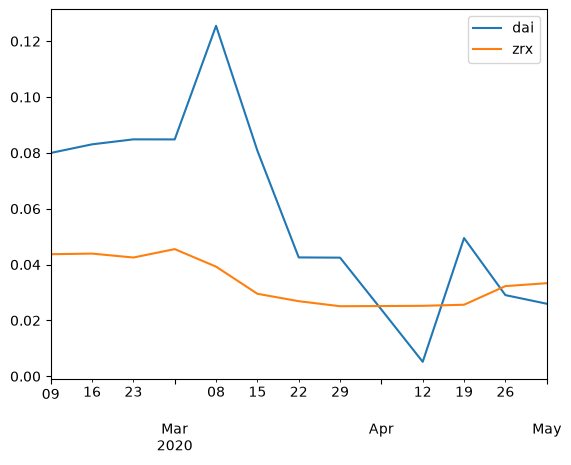

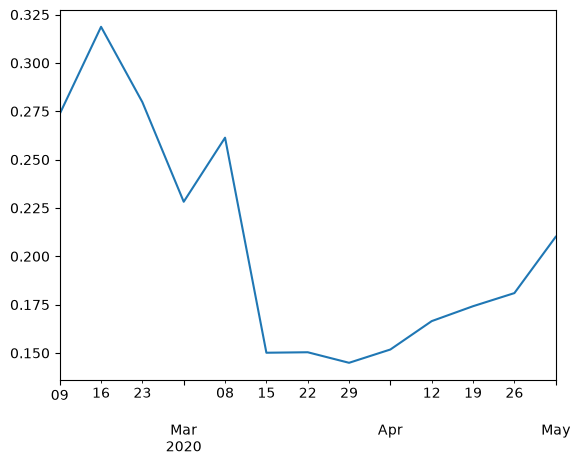

UIP does not hold.
Plot; base token: zrx, Quote token: sai


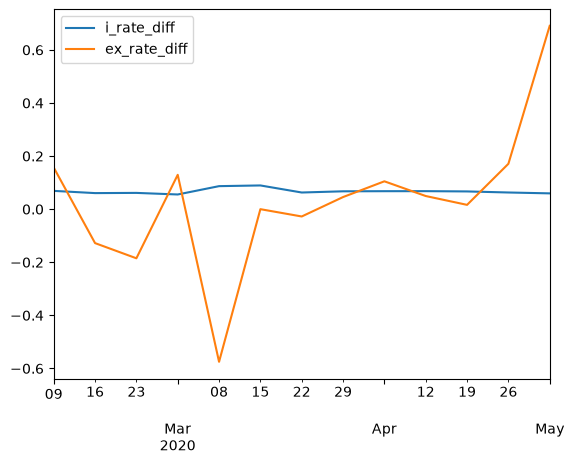

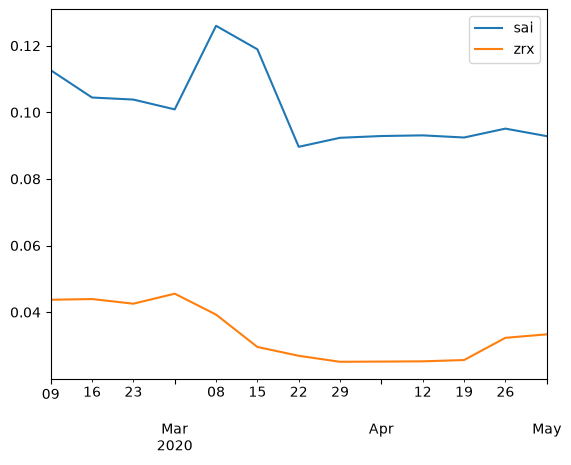

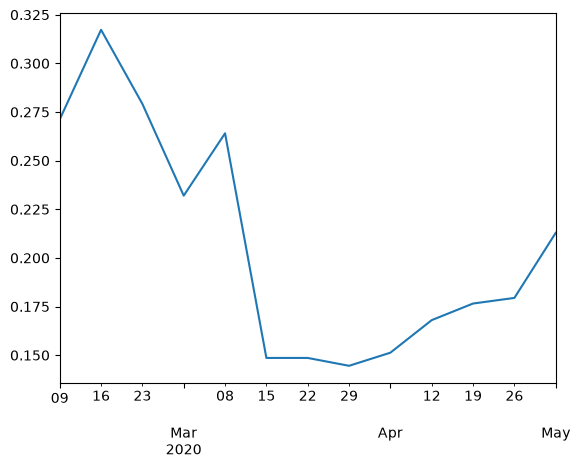

UIP holds.
Plot; base token: zrx, Quote token: rep


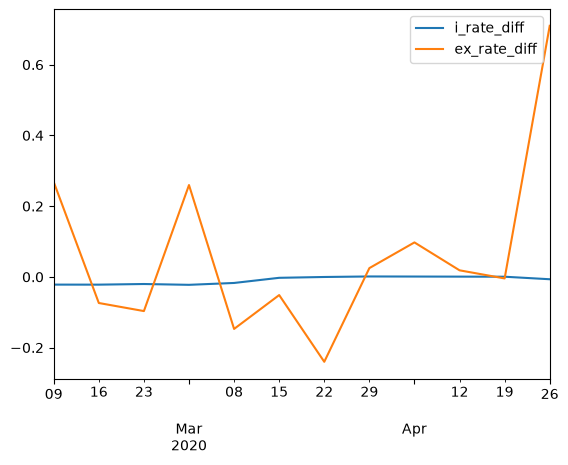

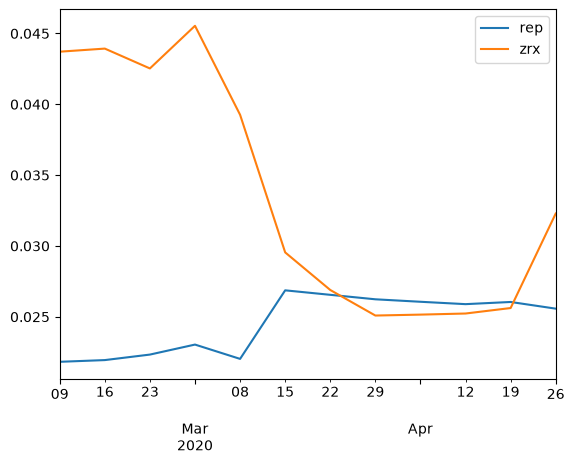

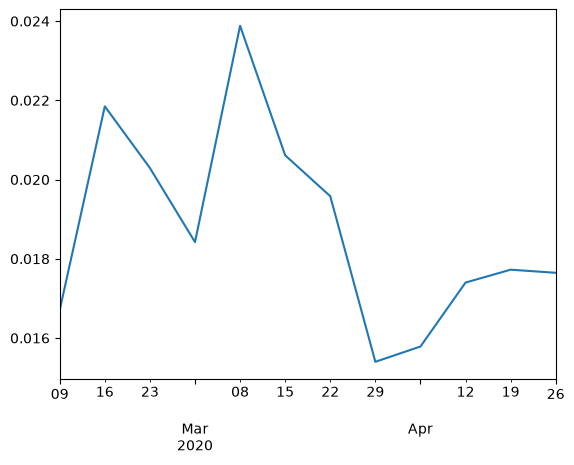

UIP holds.
Plot; base token: usdc, Quote token: dai


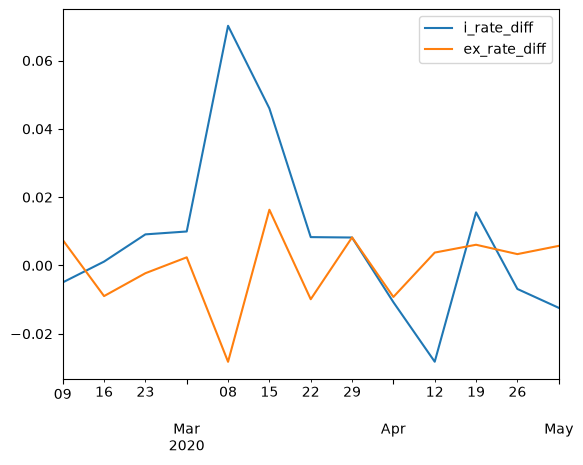

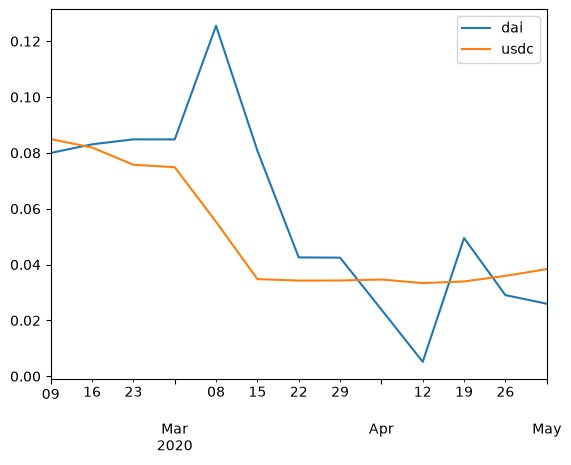

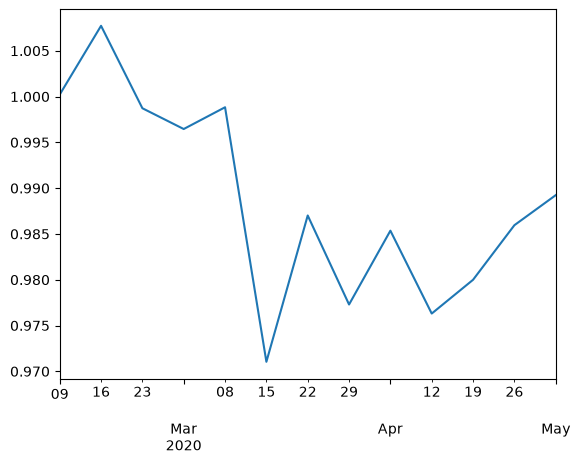

UIP does not hold.
Plot; base token: usdc, Quote token: sai


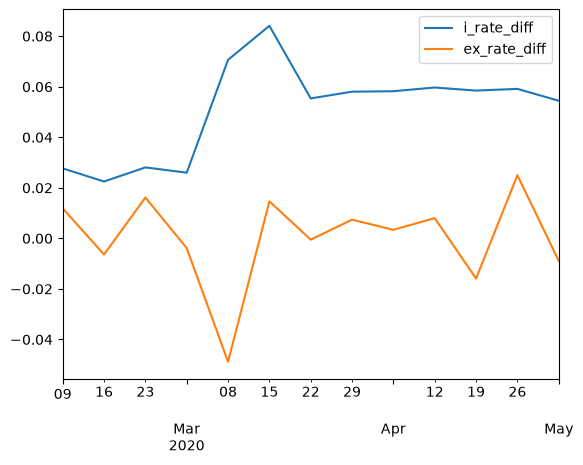

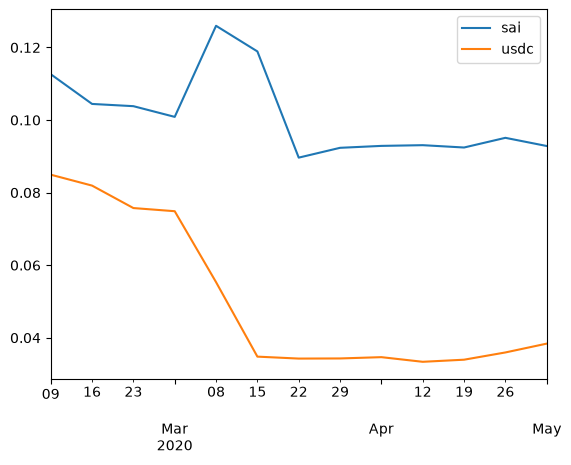

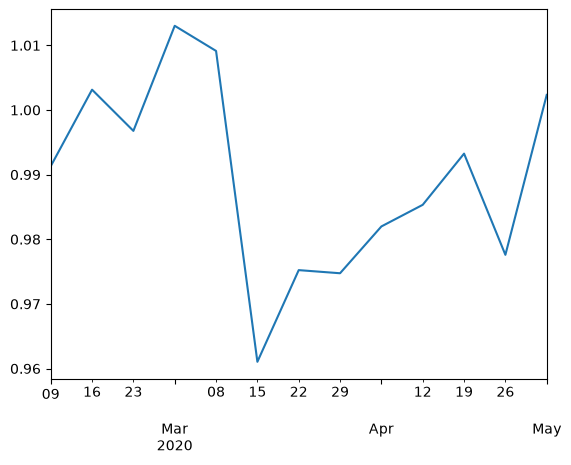

UIP does not hold.
Plot; base token: usdc, Quote token: rep


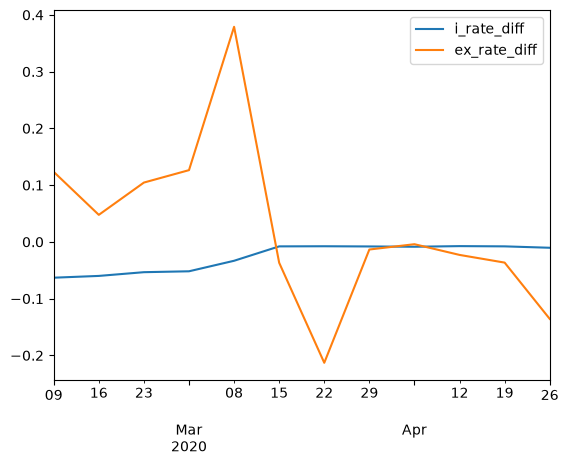

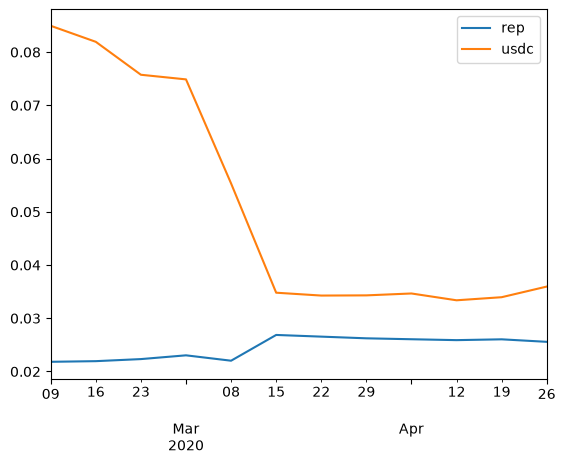

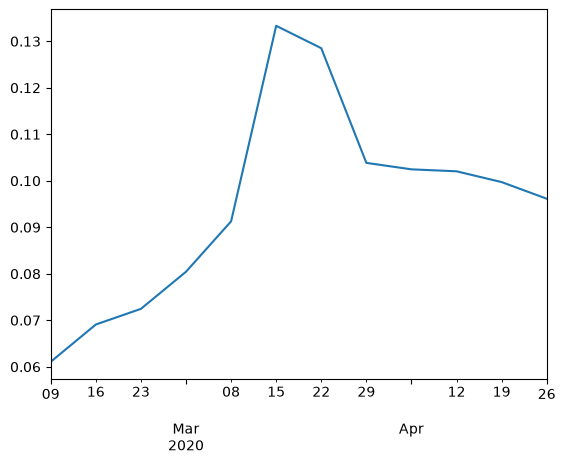

UIP does not hold.
Plot; base token: dai, Quote token: sai


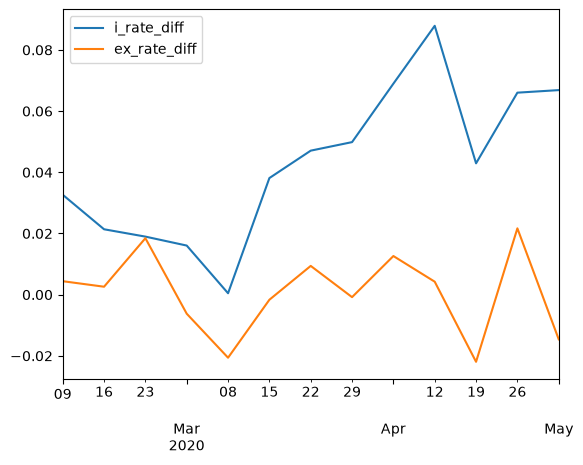

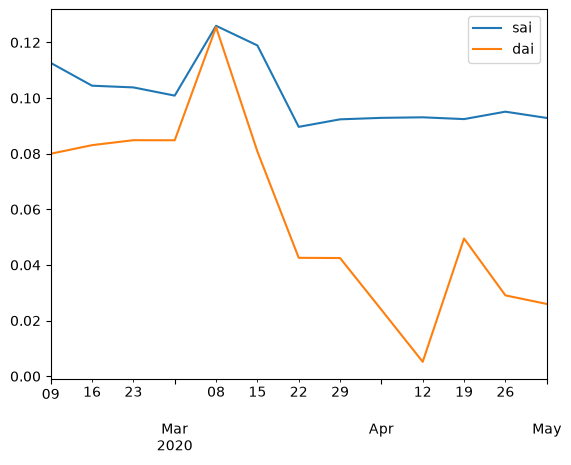

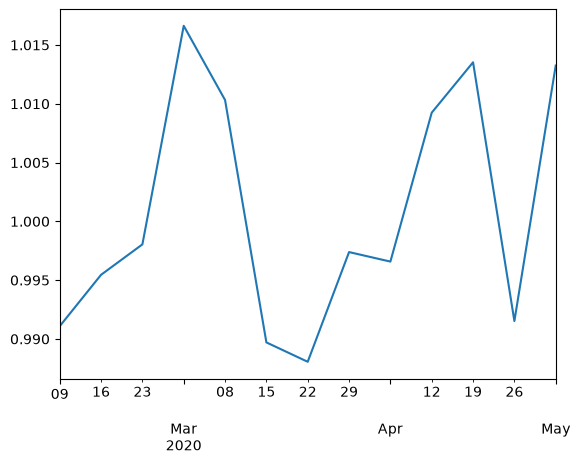

UIP does not hold.
Plot; base token: dai, Quote token: rep


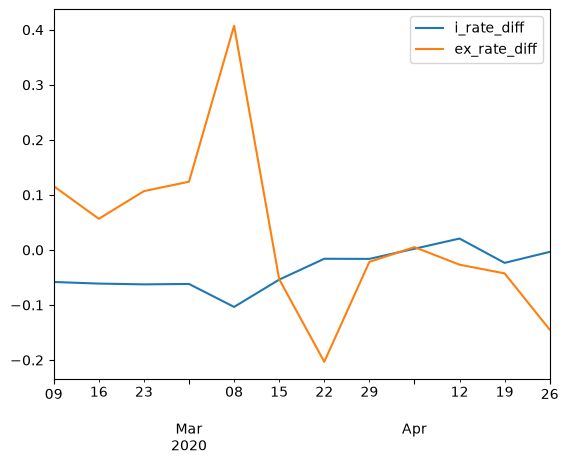

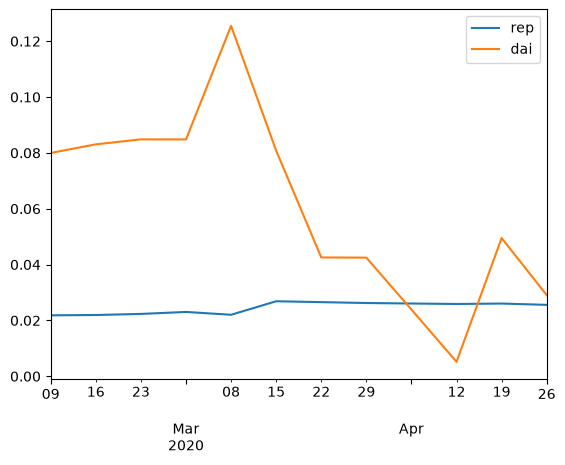

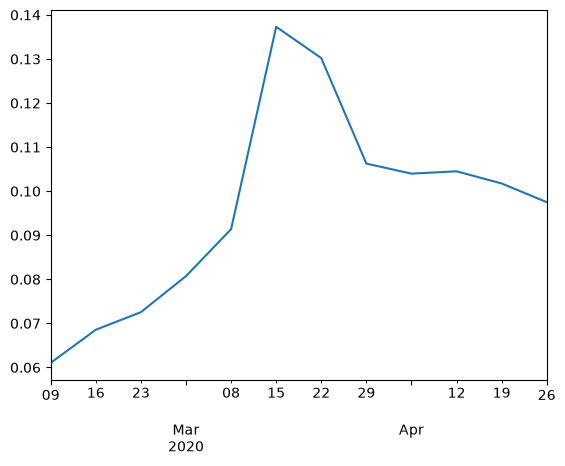

UIP does not hold.
UIP holds: {'eth_bat': np.float64(0.08140635460787418), 'eth_zrx': np.float64(0.5613426304557597), 'eth_usdc': np.float64(0.38325663798460186), 'eth_sai': np.float64(0.10267543648015351), 'eth_rep': np.float64(0.8923468194801585), 'bat_zrx': np.float64(0.2824285226005855), 'bat_sai': np.float64(0.061886377279332216), 'bat_rep': np.float64(0.3483325748309555), 'zrx_usdc': np.float64(0.35618074163032754), 'zrx_sai': np.float64(0.08050934984192812), 'zrx_rep': np.float64(0.33745308209818753)}
UIP does not hold: {'eth_dai': np.float64(0.032161445610417456), 'bat_usdc': np.float64(0.013372422469358691), 'bat_dai': np.float64(0.014772716816925777), 'zrx_dai': np.float64(0.0007384724563985075), 'usdc_dai': np.float64(1.0592550230076855e-05), 'usdc_sai': np.float64(3.072859191856459e-08), 'usdc_rep': np.float64(0.0027153008893688584), 'dai_sai': np.float64(1.3785572128589666e-09), 'dai_rep': np.float64(0.0007130988647930444)}
\begin{tabular}{lllllllll}
\toprule
pair & n-obs 

In [19]:
## Weekly, borrow
regression_runner(frequency='W', side='borrow')

Plot; base token: eth, Quote token: bat


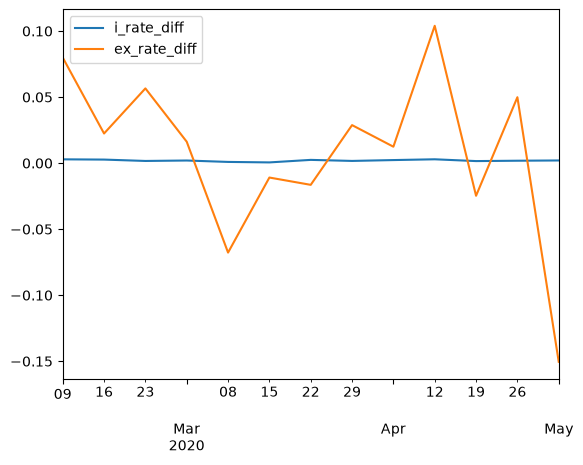

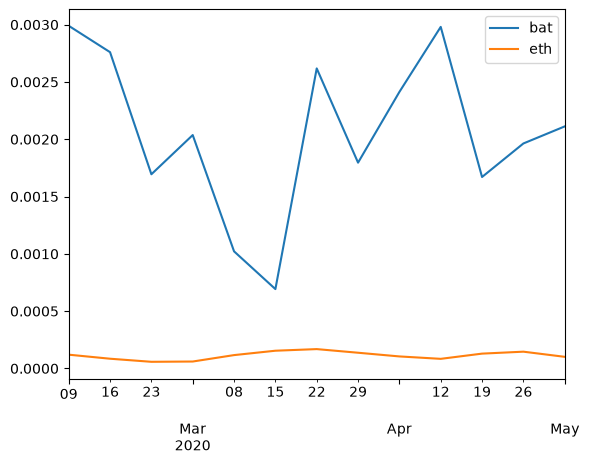

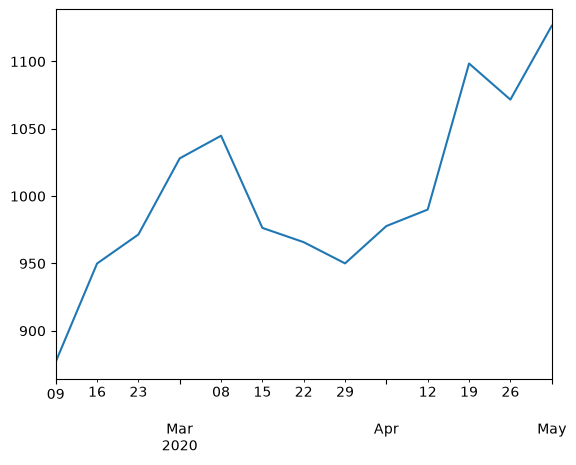

UIP holds.
Plot; base token: eth, Quote token: zrx


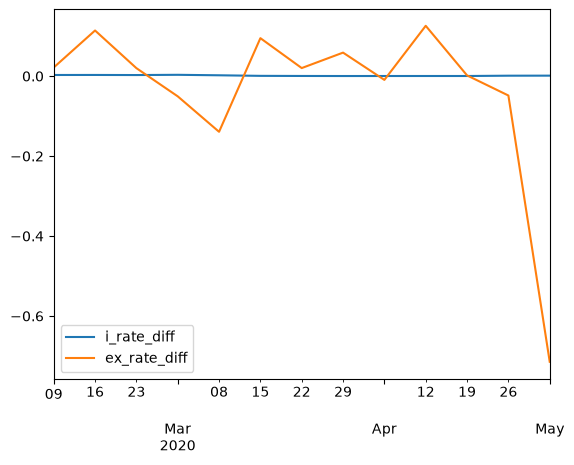

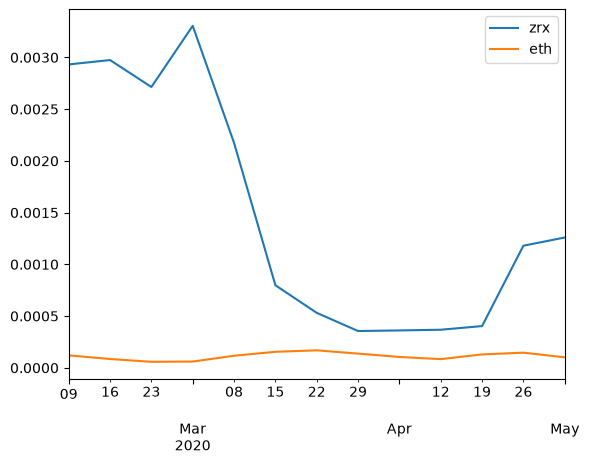

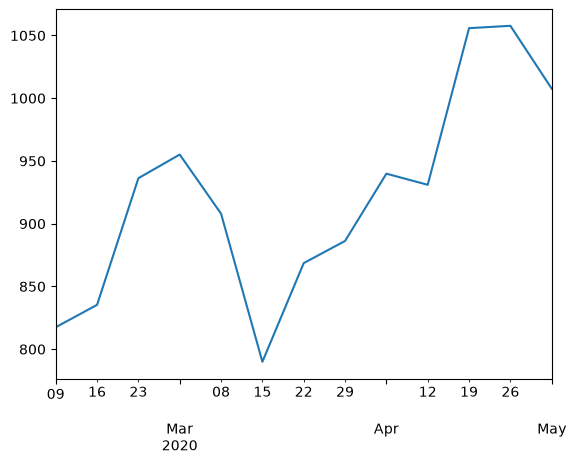

UIP holds.
              eth_usdc      usdc       eth
2020-02-02  183.096449  0.048331  0.000135
2020-02-09  223.645194  0.049035  0.000120
2020-02-16  264.172929  0.045162  0.000085
2020-02-23  262.217776  0.037600  0.000058
2020-03-01  218.740060  0.036812  0.000060
2020-03-08  237.585665  0.018664  0.000116
2020-03-15  122.127532  0.004758  0.000155
2020-03-22  132.332452  0.004408  0.000169
2020-03-29  131.417426  0.004421  0.000137
2020-04-05  144.795176  0.004584  0.000105
2020-04-12  158.756430  0.004022  0.000084
2020-04-19  187.672423  0.004271  0.000129
2020-04-26  194.139577  0.005175  0.000146
2020-05-03  214.003359  0.006447  0.000101
2020-05-10  210.842570  0.011326  0.000091
Plot; base token: eth, Quote token: usdc


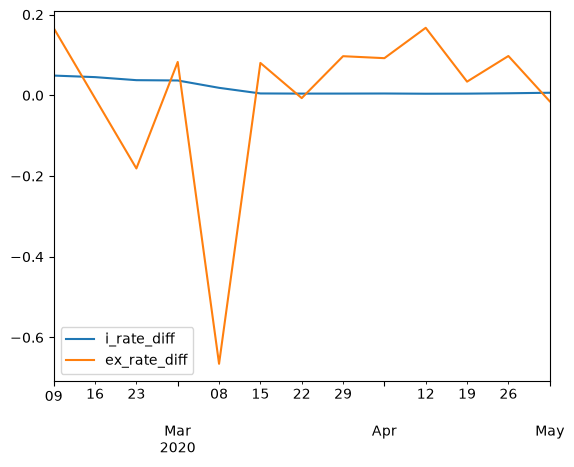

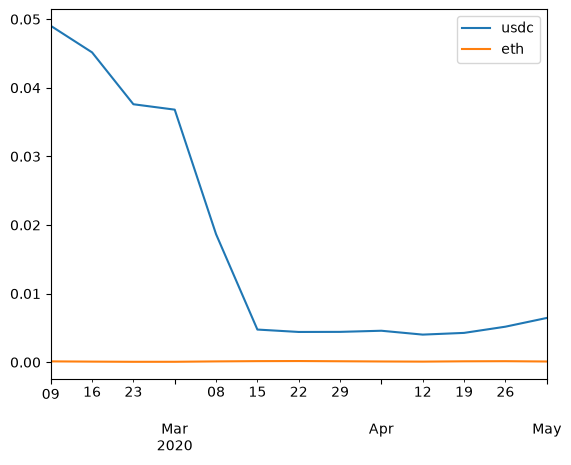

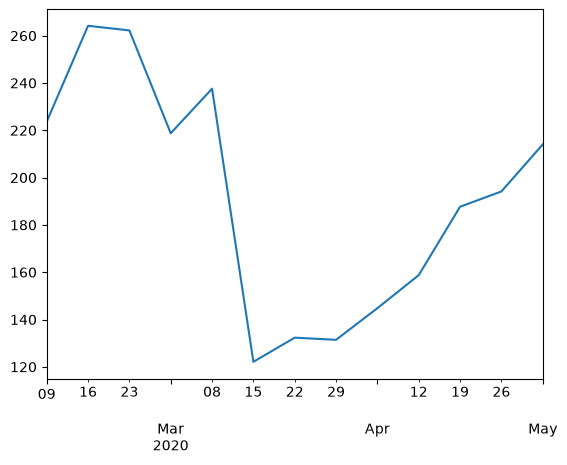

UIP holds.
Plot; base token: eth, Quote token: dai


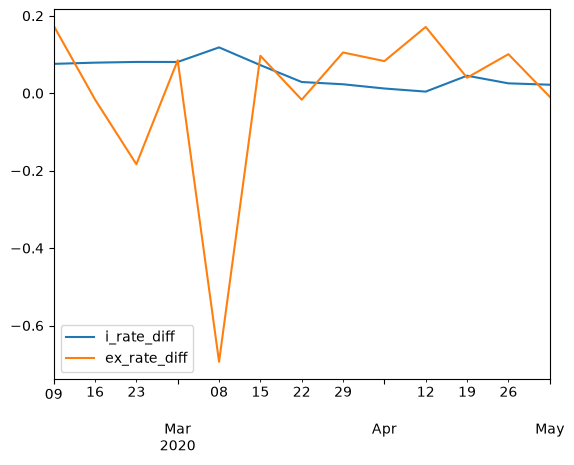

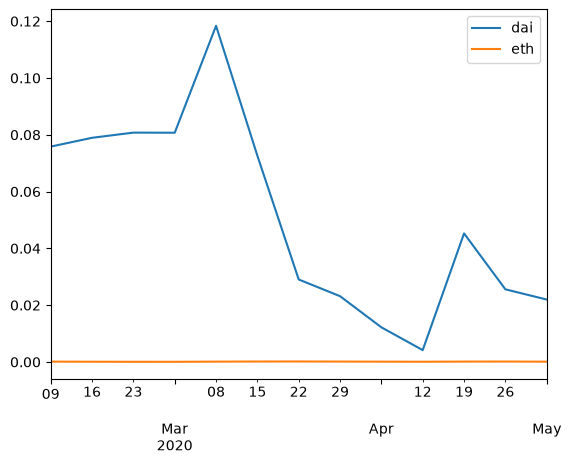

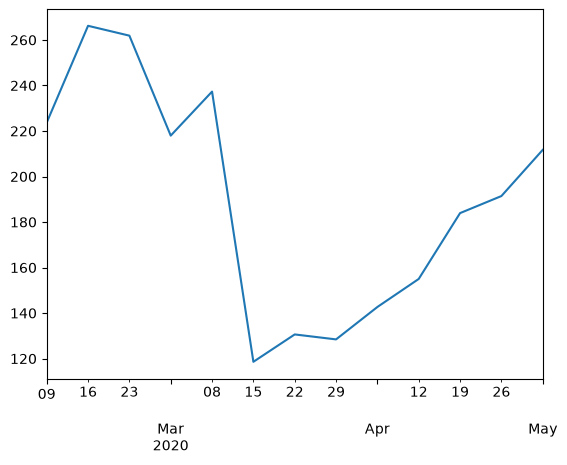

UIP does not hold.
Plot; base token: eth, Quote token: sai


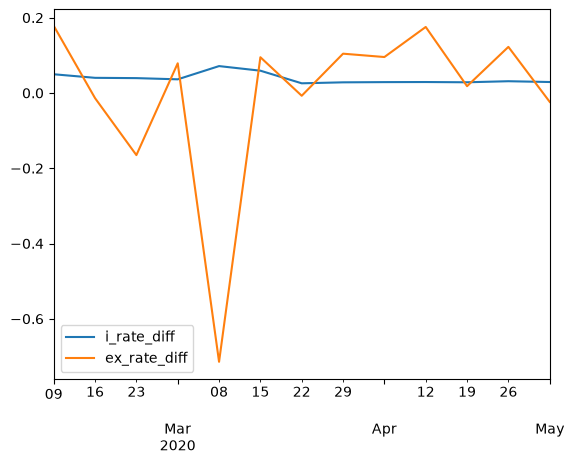

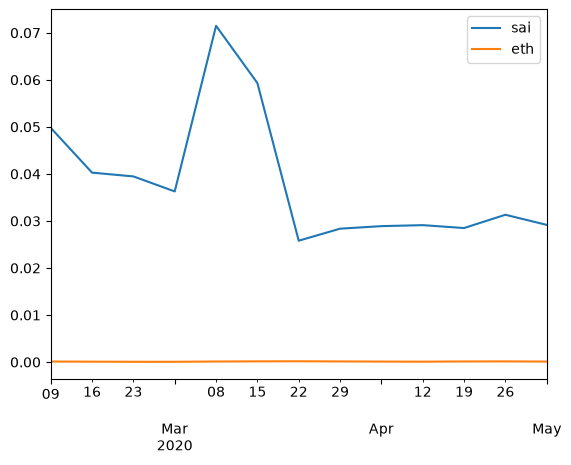

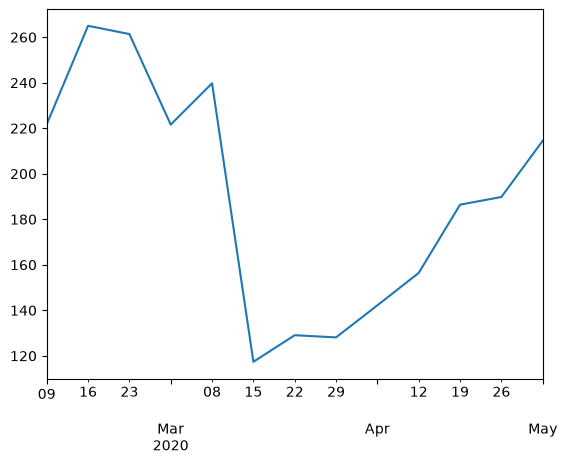

UIP holds.
Plot; base token: eth, Quote token: rep


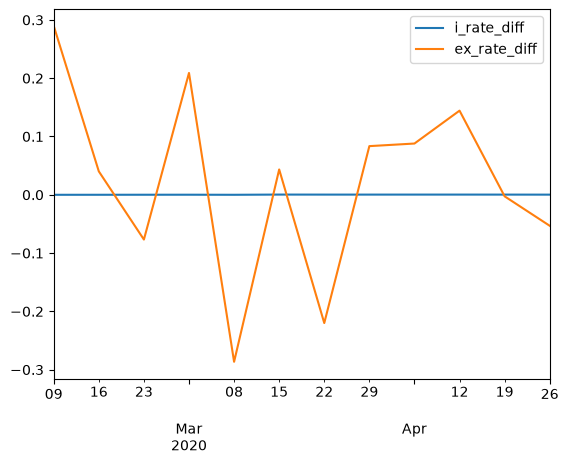

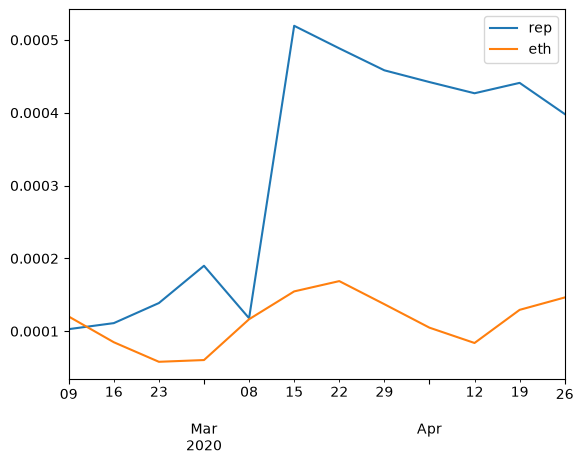

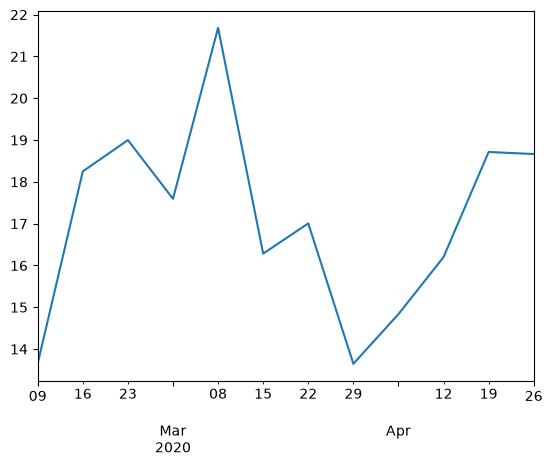

UIP holds.
Plot; base token: bat, Quote token: zrx


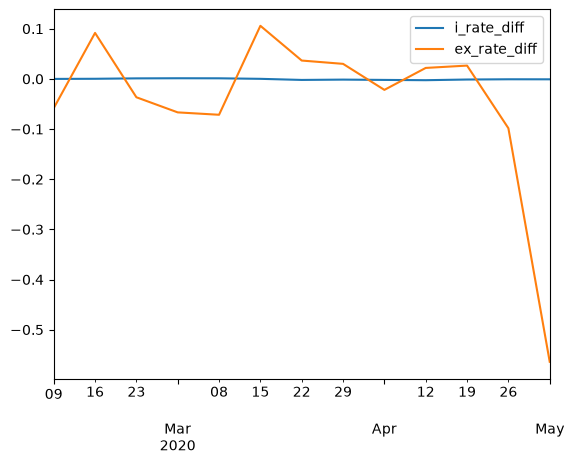

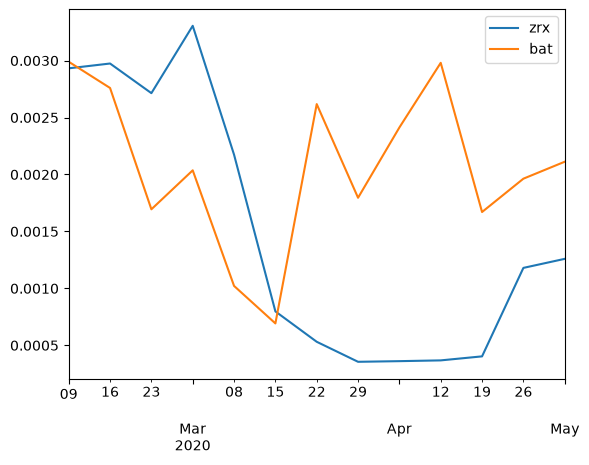

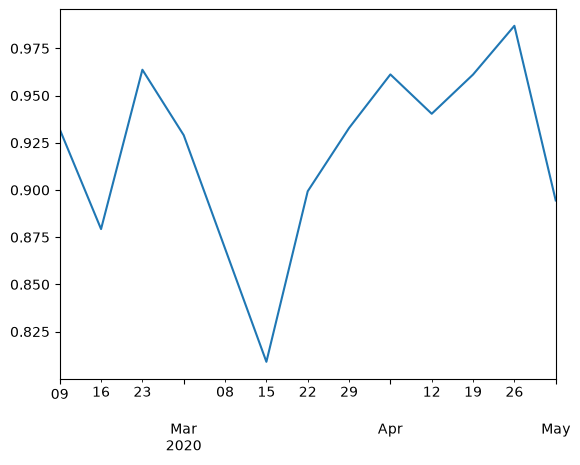

UIP holds.
Plot; base token: bat, Quote token: usdc


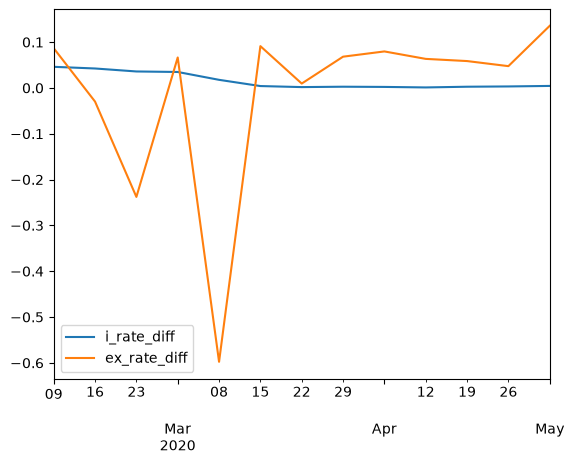

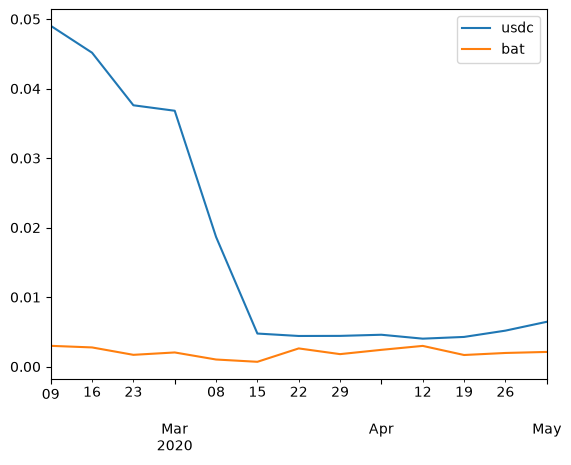

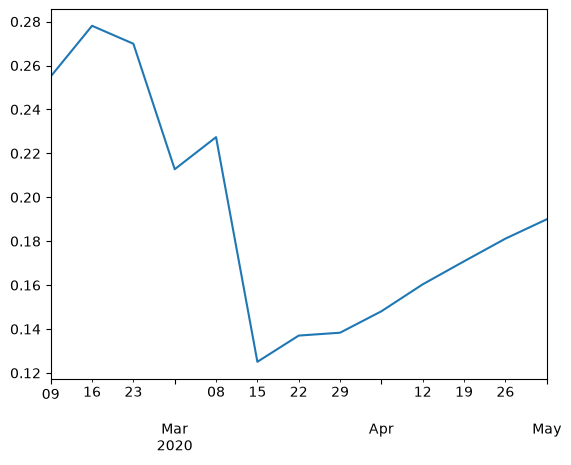

UIP holds.
Plot; base token: bat, Quote token: dai


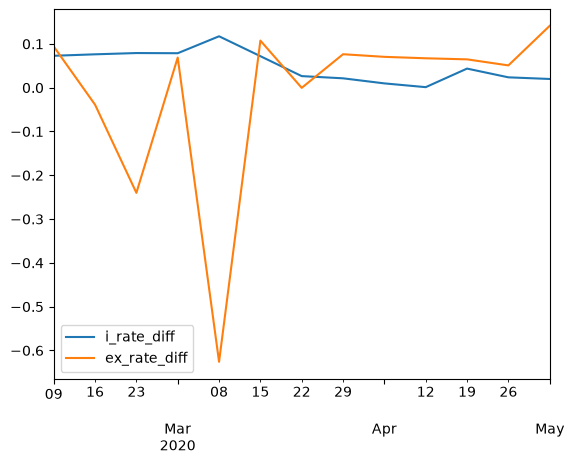

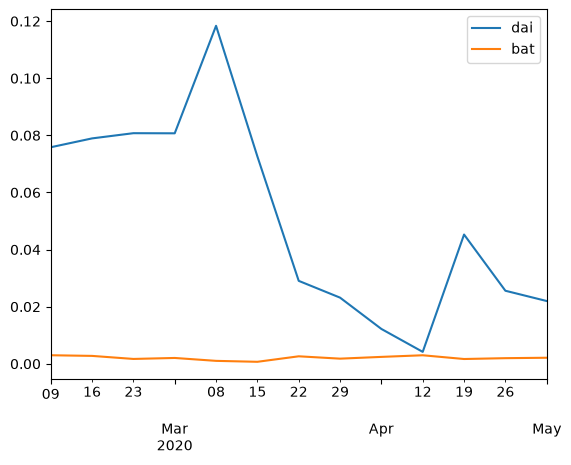

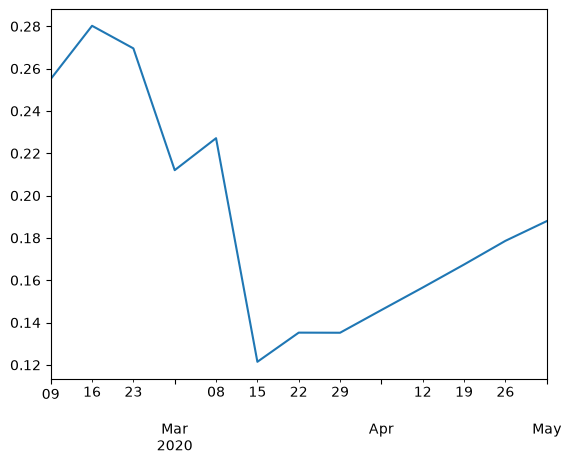

UIP does not hold.
Plot; base token: bat, Quote token: sai


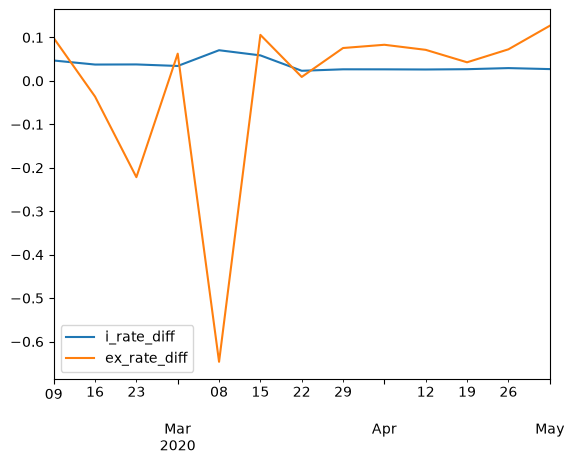

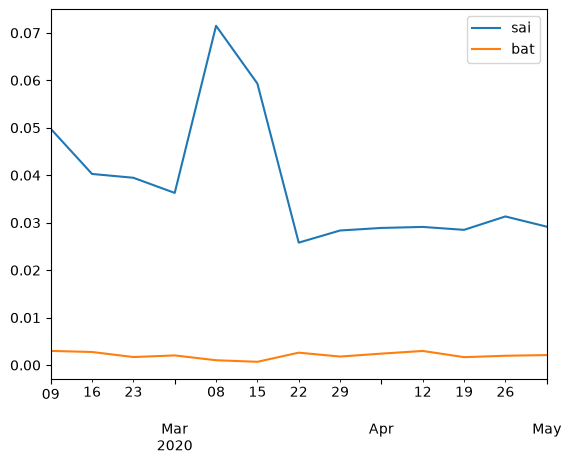

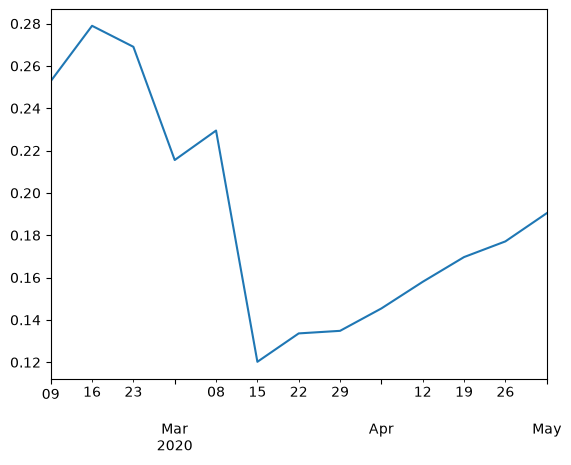

UIP holds.
Plot; base token: bat, Quote token: rep


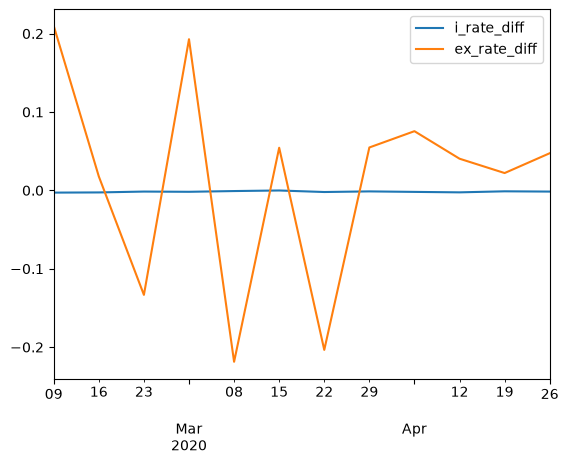

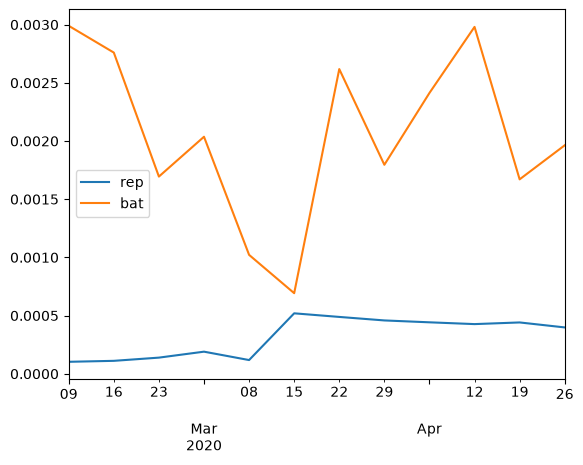

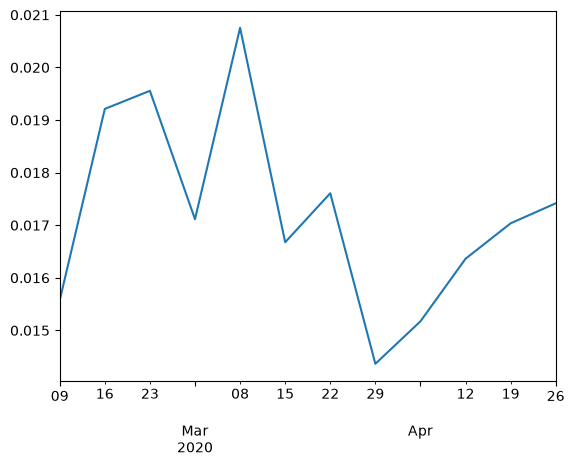

UIP holds.
Plot; base token: zrx, Quote token: usdc


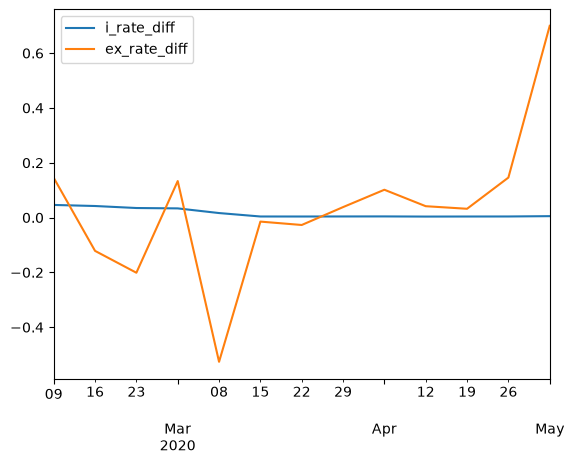

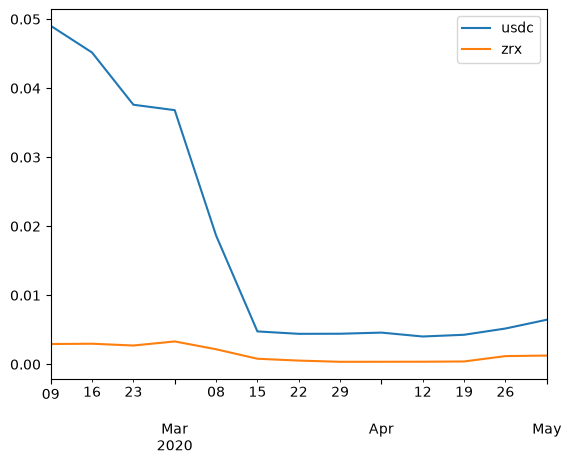

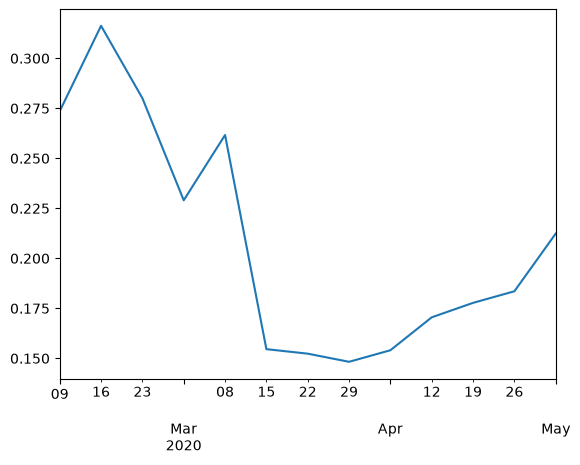

UIP holds.
Plot; base token: zrx, Quote token: dai


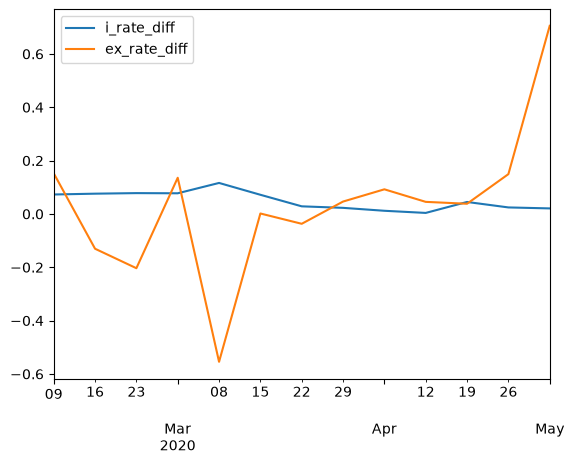

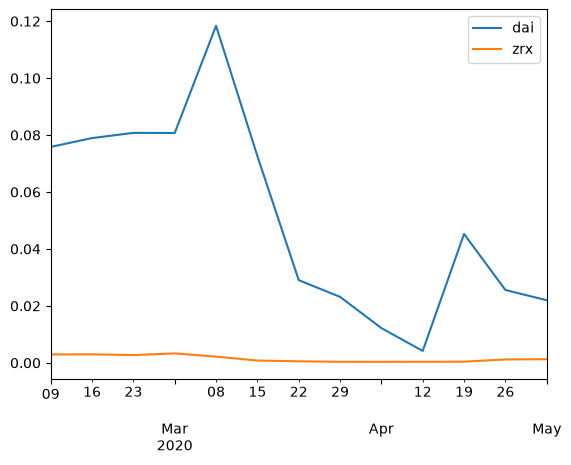

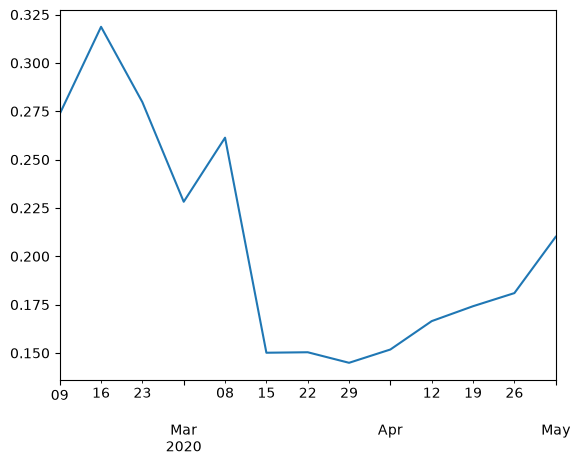

UIP does not hold.
Plot; base token: zrx, Quote token: sai


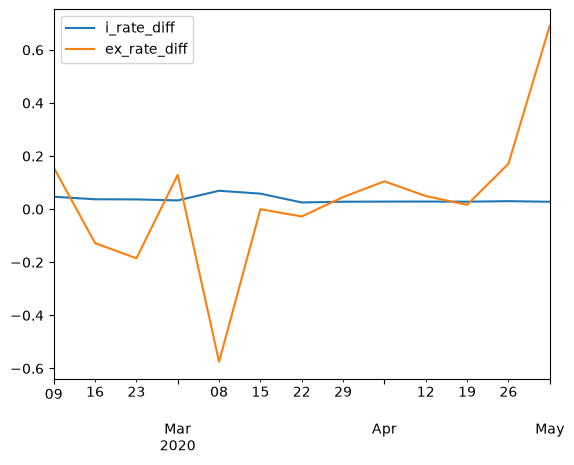

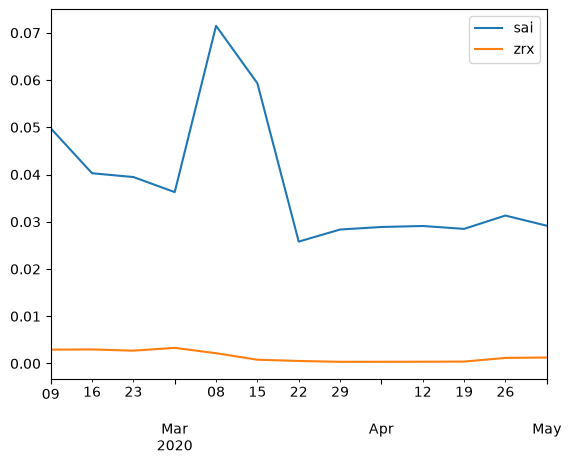

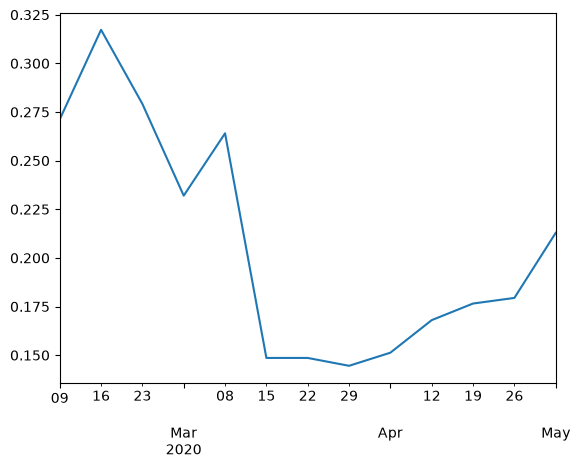

UIP does not hold.
Plot; base token: zrx, Quote token: rep


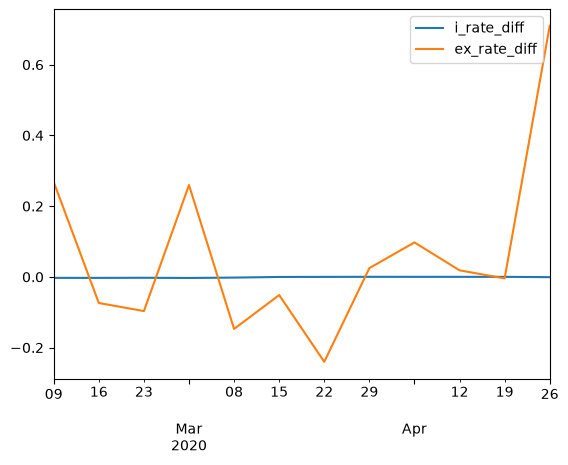

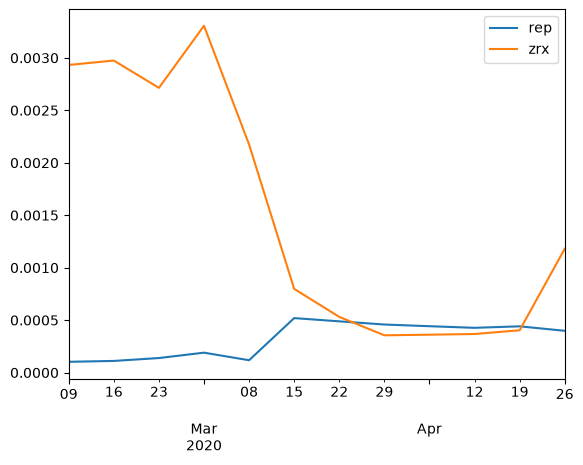

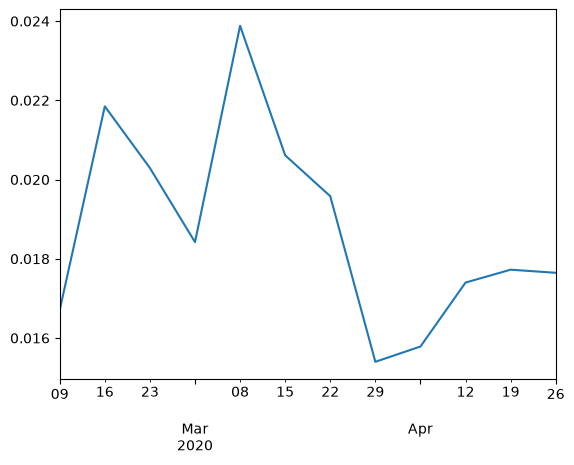

UIP holds.
Plot; base token: usdc, Quote token: dai


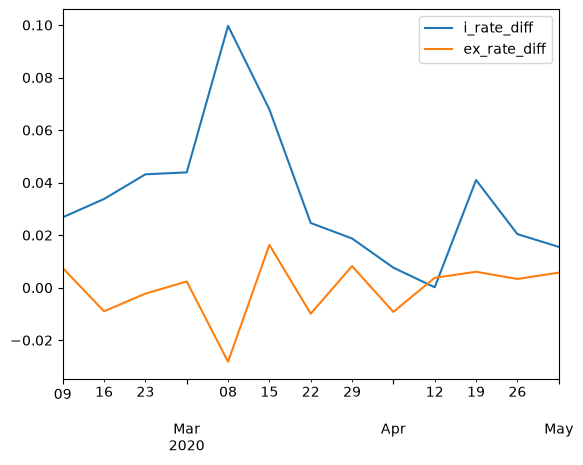

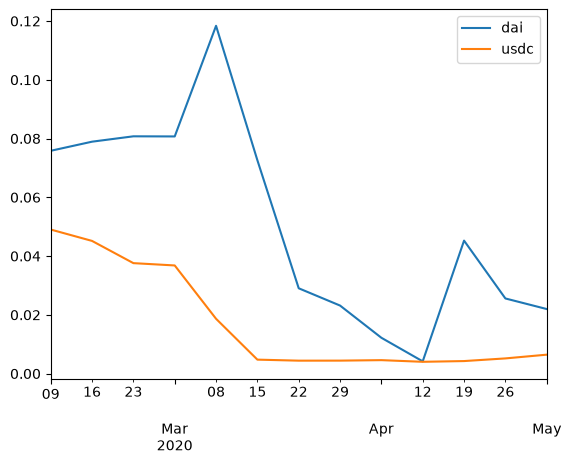

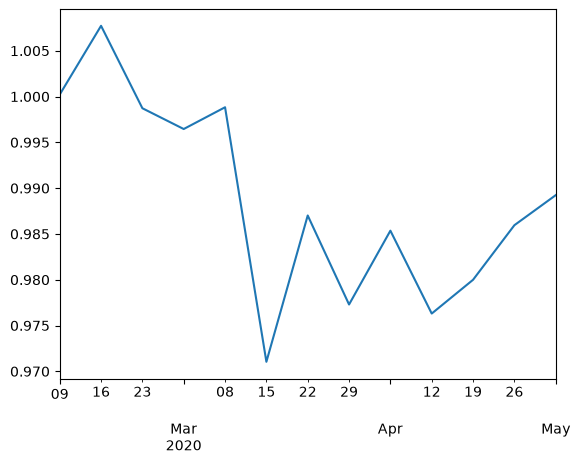

UIP does not hold.
Plot; base token: usdc, Quote token: sai


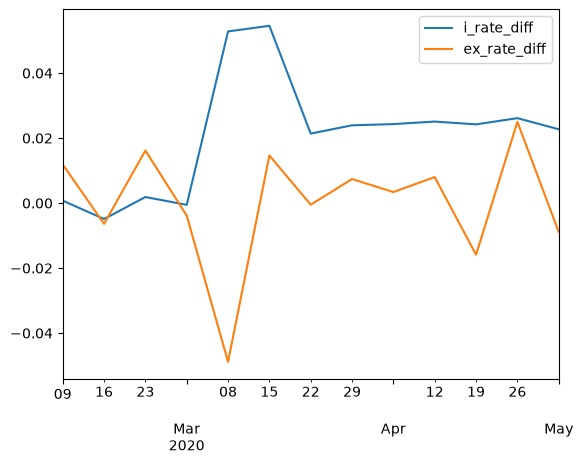

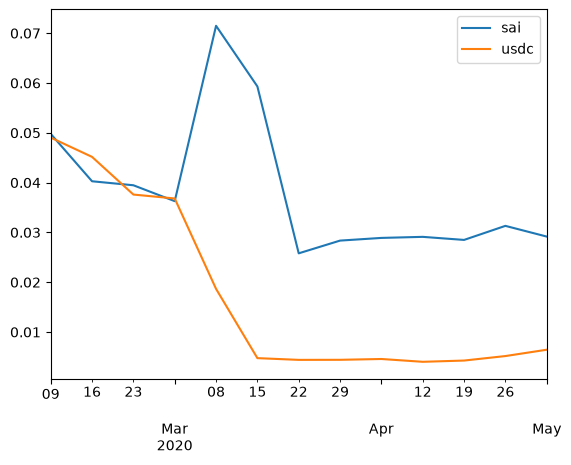

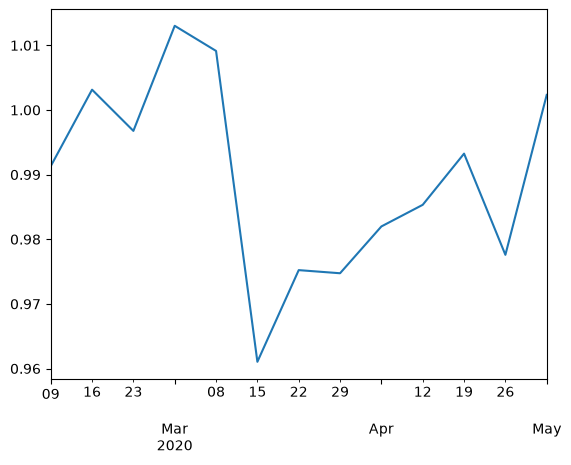

UIP does not hold.
Plot; base token: usdc, Quote token: rep


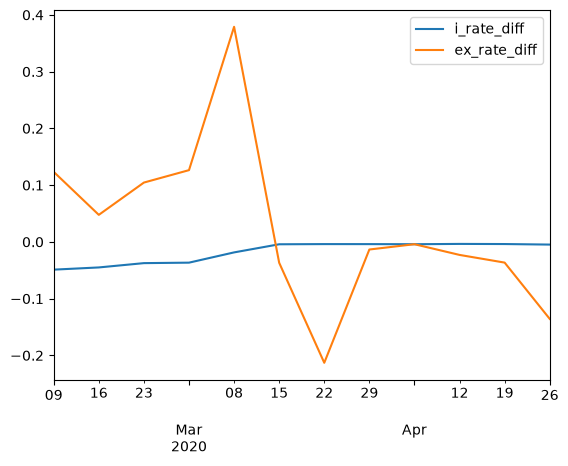

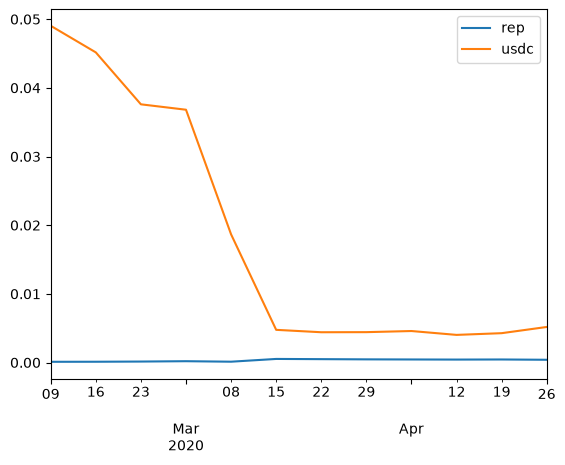

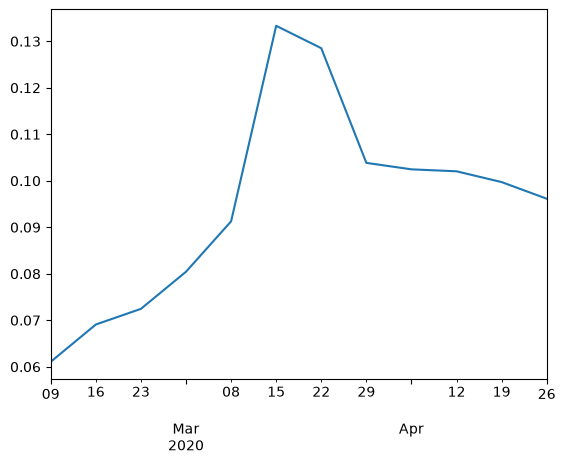

UIP does not hold.
Plot; base token: dai, Quote token: sai


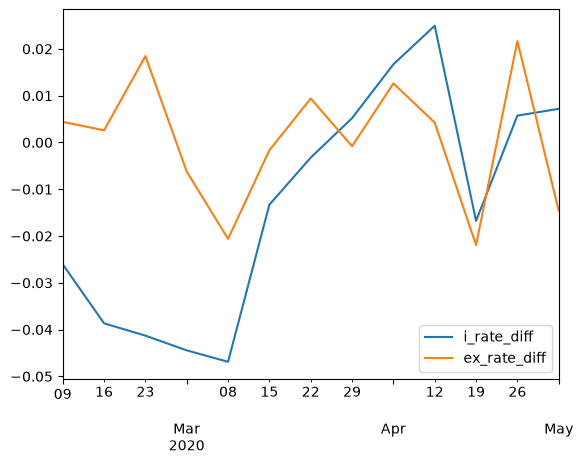

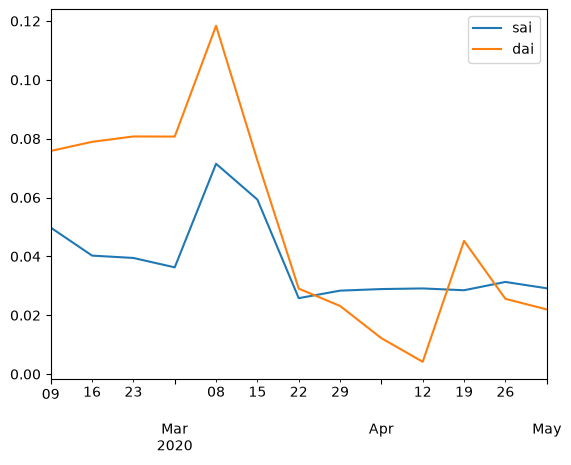

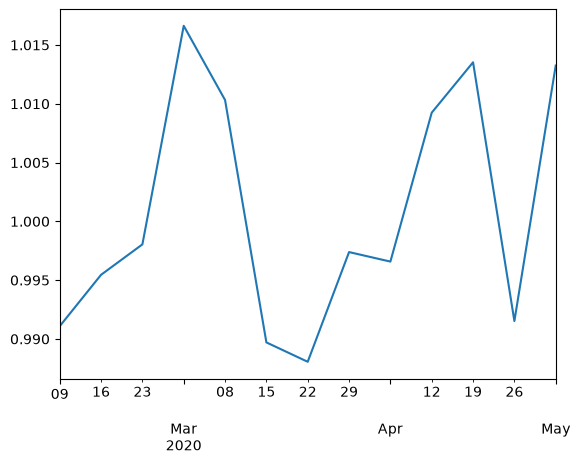

UIP does not hold.
Plot; base token: dai, Quote token: rep


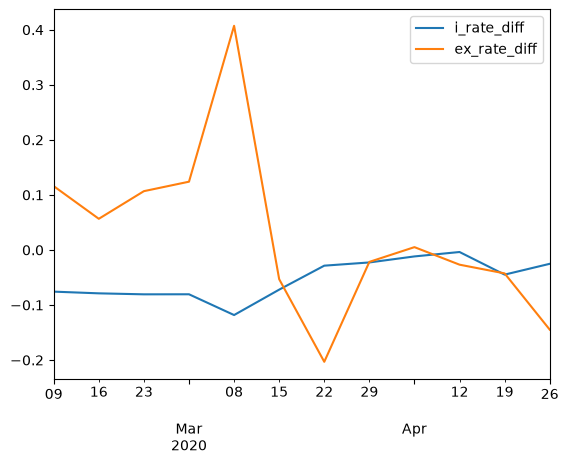

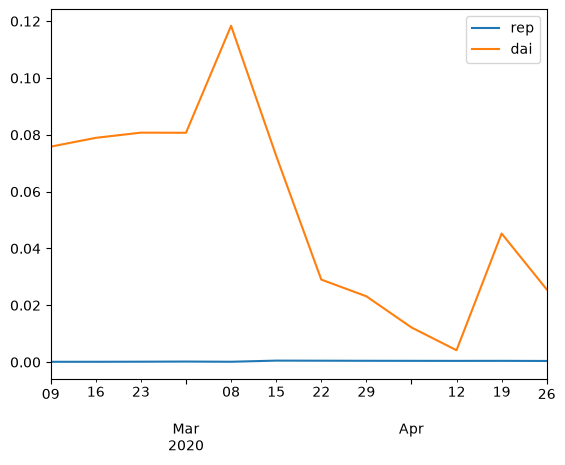

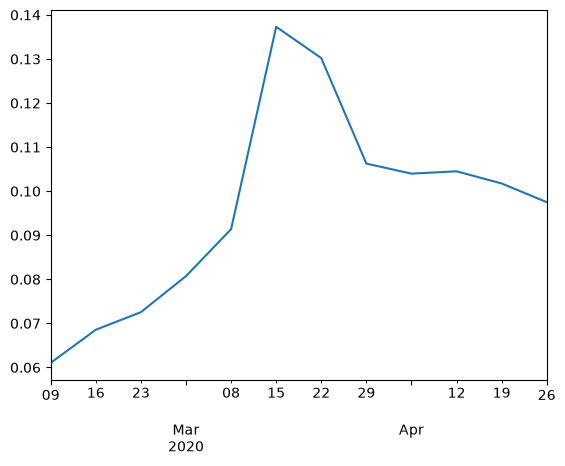

UIP does not hold.
UIP holds: {'eth_bat': np.float64(0.08919982697114491), 'eth_zrx': np.float64(0.7474848209459252), 'eth_usdc': np.float64(0.5711317080289202), 'eth_sai': np.float64(0.11471343825927807), 'eth_rep': np.float64(0.8152848278511029), 'bat_zrx': np.float64(0.36776864251933256), 'bat_usdc': np.float64(0.2028884081968294), 'bat_sai': np.float64(0.07883389815701976), 'bat_rep': np.float64(0.5317628328243537), 'zrx_usdc': np.float64(0.3319220465365703), 'zrx_rep': np.float64(0.4147314785994211)}
UIP does not hold: {'eth_dai': np.float64(0.039377342489695065), 'bat_dai': np.float64(0.015803649347365653), 'zrx_dai': np.float64(0.005786595949940199), 'zrx_sai': np.float64(0.027637692730009433), 'usdc_dai': np.float64(1.1008963333243018e-09), 'usdc_sai': np.float64(0.000421279735411451), 'usdc_rep': np.float64(0.0029029365602167264), 'dai_sai': np.float64(0.00022972001218627468), 'dai_rep': np.float64(0.0003577347116376114)}
\begin{tabular}{lllllllll}
\toprule
pair & n-obs & alph

In [20]:
## Weekly, supply
regression_runner(frequency='W', side='supply')